# TSARA, Phase 7 — ratios

**A walkthrough you can run, change and try to break.** Every number and figure
below is produced by the package from points drawn inside this notebook, where
the true ratio is known, or (sections 5–8) from air the generator manufactures
with every plume it injected recorded. No real measurement is read, and
nothing needs mounting.

---

## How to use this notebook

1. **Run everything once** (*Run All*, about two minutes).
2. **Every section stands on its own.** Each opens with a **parameters cell**:
   a short list of CAPITALISED names, each commented with what it controls.
   Change a value, then run that section's cells from the parameters cell down
   to the next heading. Sections share only the setup cell below.
3. **Every section prints checks.** A line beginning ✔ is a claim about TSARA,
   compared *as it ran* against something written independently in this
   notebook: York's paper written out as a plain loop, a closed form, or the
   truth the points were drawn from. The checks are written to hold at *any*
   parameters. If you ever see ✘, you have found an edge case worth
   understanding or a bug.
4. **"Try it"** notes after each section suggest a change and say what should
   happen. Each prediction was run before this notebook was committed.
5. **The last section** collects every check into one scoreboard.

---

## What this phase delivers so far

An enhancement ratio is the slope of one gas's enhancement against another's,
over a stretch of readings: plot the event on a 1:1 chart and fit a line.
Phase 7a builds the line (`tsara.ratios`, `METHODS.md` §4):

| | Property | Section |
|---|---|---|
| 1 | **Noise on both gases**: least squares reads the ratio low when the denominator gas is noisy; York's line does not | §1 |
| 2 | **The ± is precision, not proof the line fits**: York's ± is the same for a mixture as for one source; the MSWD tells them apart, read against the number of points | §2 |
| 3 | **When the declared σ's are wrong**: a wrong common scale the MSWD repairs; a wrong ratio between the two gases moves the slope itself | §3 |
| 4 | **When errors persist from reading to reading**: York's ± is too tight and the MSWD cannot see it | §4 |

Phase 7b says which stretches to fit, by grouping the events stage's events
across the sweep (`tsara.events.candidates`, `METHODS.md` §6.8):

| | Property | Section |
|---|---|---|
| 5 | **What the sweep sees inside one window**: a higher entry keeps the same intervals, fewer; exit nests; quantile moves events a little | §5 |
| 6 | **The rule**: one window's events that share a peak form a candidate, seeded by height; checked against a reference written from the rule's paragraph | §6 |
| 7 | **Is a candidate real?** On the answer key, height tells real from false and agreement across quantiles does not | §7 |
| 8 | **What the ratio stage gets**: distinct intervals to fit, one candidate per window, fragments | §8 |

What this phase does **not** do yet: fit a ratio per candidate, judge a fit or
combine its uncertainties (7c).

---

## Vocabulary used throughout

| term | meaning |
|---|---|
| **enhancement** Δ | a reading minus its baseline at one window and quantile (Phase 5) |
| **ratio** | the slope of the numerator gas's enhancement against the reference gas's, over one stretch of readings: here Δethane against Δmethane |
| **fit** / **group** | one straight line through one set of points; TSARA fits many at once, each row of the input labelled with the fit it belongs to |
| **σ** | a reading's declared standard error (its *precision*), on each axis |
| **least squares** (OLS) | the familiar line: it assumes the x axis is exact |
| **York's line** | the most likely line when both axes carry error, each point weighted by its σ on both (York et al. 2004) |
| **dilution** | least squares reading a slope low because of noise on x |
| **MSWD** | the scatter of the points about the line ÷ the scatter their declared σ's predict: about 1 when one line plus the declared noise explains the points |
| **mixture** | an event holding air from two sources with different ratios |
| **coverage** | the share of events whose true ratio lies within the fit's ± (±1σ: 68 % if the ± is right) |
| **persistence** ρ | how much of one reading's noise carries into the next: 0 for independent readings |
| **source** | an *emission* source only: a gas leak, a landfill |
| **sweep point** | one baseline window × quantile × entry × exit; the example sweep has 81, 27 per window |
| **event** | an interval the events stage reported at one sweep point: what one point sees, not a verdict (notebook 06) |
| **peak z** | how many clean spreads above plume-free air an event's tallest reading stands (notebook 06) |
| **candidate** | the events of one variable at one window that share a peak across quantile, entry and exit (§6) |
| **seed** | a candidate's tallest event, which starts it |
| **found / absorbed / absent** | a sweep point where a candidate has an event; where an event holds its peak but belongs elsewhere; where nothing holds it |
| **gate** | the height a candidate's highest peak z must reach to be believed (the ratio stage's setting, default 5) |
| **plume / fragment / false** | what the answer key says a candidate is: holding a true plume's peak; carrying real plume air but no peak; carrying none |

---
## Setup (run this cell first)

The **toolkit**: imports, the figure style shared by notebooks 01–07, the
**reference implementations** every check compares TSARA against, the
scoreboard, and the **recipes** that draw points with a known ratio.

In [1]:
# =============================================================================
# TOOLKIT. Every section needs this cell and nothing else from other sections.
# =============================================================================
import logging
from functools import cache
from types import SimpleNamespace

import matplotlib.dates as mdates
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.stats import chi2

from tsara import setup_logging
from tsara.baseline import baseline_state
from tsara.config.analysis import BaselineConfig, EventsConfig
from tsara.config.synthetic import SyntheticConfig
from tsara.core.propagation import n_effective
from tsara.events import event_candidates, event_catalog, event_state
from tsara.ratios import FitStatus, ols, york
from tsara.synthetic import generate

# --- 1. figure style (identical to notebooks 01-06) --------------------------
C1, C2, C3 = "#0072b2", "#e69f00", "#009e73"  # Okabe-Ito blue, amber, green: colour-blind safe
C4 = "#cc79a7"  # Okabe-Ito purple, for a fourth series
INK, INK2, MUTED = "#0b0b0b", "#52514e", "#898781"
GRID, SURFACE = "#e1e0d9", "#fcfcfb"
plt.rcParams.update(
    {
        "figure.facecolor": SURFACE,
        "axes.facecolor": SURFACE,
        "savefig.facecolor": SURFACE,
        "axes.edgecolor": "#c3c2b7",
        "axes.linewidth": 0.8,
        "axes.labelcolor": INK2,
        "axes.titlecolor": INK,
        "axes.titlesize": 11,
        "axes.titleweight": "normal",
        "axes.titlelocation": "left",
        "axes.labelsize": 9.5,
        "axes.spines.top": False,
        "axes.spines.right": False,
        "xtick.color": MUTED,
        "ytick.color": MUTED,
        "xtick.labelsize": 8.5,
        "ytick.labelsize": 8.5,
        "grid.color": GRID,
        "grid.linewidth": 0.7,
        "grid.linestyle": "-",
        "legend.frameon": False,
        "legend.fontsize": 9,
        "font.size": 9.5,
        "lines.linewidth": 1.4,
        "figure.dpi": 110,
    }
)


def finish(
    ax, title=None, sub=None, ylab=None, xlab=None, legend=False, grid_axis="y", loc="upper right"
):
    """Apply the shared chrome: left-aligned title, muted subtitle, hairline grid."""
    if title:
        ax.set_title(title, pad=19 if sub else 8)
    if sub:
        ax.text(0, 1.025, sub, transform=ax.transAxes, fontsize=8.8, color=MUTED, va="bottom")
    if ylab:
        ax.set_ylabel(ylab)
    if xlab:
        ax.set_xlabel(xlab)
    if grid_axis:
        ax.grid(True, axis=grid_axis, alpha=0.9)
    ax.set_axisbelow(True)
    if legend:
        ax.legend(loc=loc)


# --- 2. reference implementations --------------------------------------------
# Written from the papers, deliberately slow and plain: one fit at a time, in
# York's own notation. They share no code with TSARA. If TSARA and these agree,
# it is because both compute the definition.


def reference_york(x, y, sx, sy, r=0.0):
    """York et al. (2004), section III, written out for one fit.

    Weights w(X) = 1/sx², w(Y) = 1/sy², α = sqrt(w(X) w(Y)). Starting from least
    squares, repeat: W = w(X) w(Y) / (w(X) + b² w(Y) − 2 b r α); X̄, Ȳ the
    W-weighted means; U = X − X̄, V = Y − Ȳ;
    β = W [U / w(Y) + b V / w(X) − (b U + V) r / α]; b = Σ W β V / Σ W β U.
    Then a = Ȳ − b X̄, and σ_b² = 1 / Σ W u², u the adjusted points' spread.
    Returns slope, intercept, slope sigma.
    """
    x, y = np.asarray(x, float), np.asarray(y, float)
    wx = np.broadcast_to(1 / np.square(sx), x.shape)
    wy = np.broadcast_to(1 / np.square(sy), x.shape)
    alpha = np.sqrt(wx * wy)
    b = np.polyfit(x, y, 1)[0]
    for _ in range(10_000):
        w = wx * wy / (wx + b * b * wy - 2 * b * r * alpha)
        u, v = x - np.sum(w * x) / np.sum(w), y - np.sum(w * y) / np.sum(w)
        beta = w * (u / wy + b * v / wx - (b * u + v) * r / alpha)
        new = np.sum(w * beta * v) / np.sum(w * beta * u)
        if abs(new - b) <= 1e-15 * abs(new):
            b = new
            break
        b = new
    w = wx * wy / (wx + b * b * wy - 2 * b * r * alpha)
    x_bar, y_bar = np.sum(w * x) / np.sum(w), np.sum(w * y) / np.sum(w)
    beta = w * (
        (x - x_bar) / wy + b * (y - y_bar) / wx - (b * (x - x_bar) + (y - y_bar)) * r / alpha
    )
    adjusted = x_bar + beta
    spread = adjusted - np.sum(w * adjusted) / np.sum(w)
    return b, y_bar - b * x_bar, 1 / np.sqrt(np.sum(w * spread**2))


def reference_ols(x, y):
    """Least squares from the textbook: slope Σ(x−x̄)(y−ȳ) / Σ(x−x̄)², one fit."""
    x, y = np.asarray(x, float), np.asarray(y, float)
    dx, dy = x - x.mean(), y - y.mean()
    return np.sum(dx * dy) / np.sum(dx * dx)


def reference_candidates(catalog):
    """Apply METHODS §6.8's candidate rule one event at a time; return each event's seed.

    For one variable at one window, order its events at every quantile, entry
    and exit by peak z, tallest first (a tie to the earlier peak, then to the
    earlier sweep point). The tallest event not yet taken is a seed. At every
    other sweep point, the event whose interval holds the seed's peak (start <=
    peak < end; of two, the later-starting) joins it when no seed has taken it
    and the seed's interval holds its peak in turn. Returns {event_id: the
    event_id of its seed} for every event that found its own events.
    """
    seed_of = {}
    own = catalog[catalog["trigger_event_id"].isna()]
    for _, window in own.groupby(["instrument", "species", "baseline_window"]):
        events = window.to_dict("records")
        at = {}  # sweep point -> its events
        for e in events:
            at.setdefault(
                (e["baseline_quantile"], e["enter_multiple"], e["exit_multiple"]), []
            ).append(e)

        def point(e):
            return (e["baseline_quantile"], e["enter_multiple"], e["exit_multiple"])

        for seed in sorted(events, key=lambda e: (-e["peak_z"], e["peak_time"], point(e))):
            if seed["event_id"] in seed_of:
                continue
            seed_of[seed["event_id"]] = seed["event_id"]
            for p, there in at.items():
                if p == point(seed):
                    continue
                holders = [e for e in there if e["start_time"] <= seed["peak_time"] < e["end_time"]]
                if not holders:
                    continue
                held = max(holders, key=lambda e: e["start_time"])
                mutual = seed["start_time"] <= held["peak_time"] < seed["end_time"]
                if held["event_id"] not in seed_of and mutual:
                    seed_of[held["event_id"]] = seed["event_id"]
    return seed_of


# --- 3. the scoreboard -------------------------------------------------------
CHECKS = {}  # claim -> (held?, detail); the last section prints them all


def start_section(tag):
    """Forget a section's earlier checks, so re-running it replaces rather than piles up."""
    for claim in [c for c in CHECKS if c.startswith(tag + " ")]:
        del CHECKS[claim]


def check(claim, holds, detail=""):
    """Record one claim about TSARA and print whether it held just now."""
    CHECKS[claim] = (bool(holds), detail)
    mark = "✔" if holds else "✘ DOES NOT HOLD:"
    print(f"  {mark} {claim}" + (f"   [{detail}]" if detail else ""))


# --- 4. recipes ---------------------------------------------------------------
def plume_events(
    *, n_events, n_readings, peak, width_s, ratio, sigma_x, sigma_y, seed, intercept=0.0, rho=0.0
):
    """Draw `n_events` copies of one plume, with fresh noise each time.

    One plume passing the inlet: true Δmethane rises and falls as a Gaussian of
    standard deviation `width_s` seconds and height `peak`, read once a second
    for `n_readings` seconds centred on its peak. True Δethane is `ratio` times
    it, plus `intercept` (what a baseline a little off would leave). Each
    reading gets Gaussian noise, `sigma_x` on methane and `sigma_y` on ethane,
    independent from reading to reading when `rho` is 0. With `rho` above 0 each
    reading's noise keeps that share of the one before (an AR(1) process, the
    same σ at every reading): errors that persist, as in an analyzer whose cell
    takes a few seconds to flush. Returns the readings in long form, every
    event's rows labelled with its number, as TSARA's fits take them, and the
    true Δmethane.
    """
    rng = np.random.default_rng(seed)
    t = np.arange(n_readings) - (n_readings - 1) / 2
    true_x = peak * np.exp(-0.5 * (t / width_s) ** 2)
    noise_x = rng.standard_normal((n_events, n_readings))
    noise_y = rng.standard_normal((n_events, n_readings))
    if rho:
        for i in range(1, n_readings):
            noise_x[:, i] = rho * noise_x[:, i - 1] + np.sqrt(1 - rho**2) * noise_x[:, i]
            noise_y[:, i] = rho * noise_y[:, i - 1] + np.sqrt(1 - rho**2) * noise_y[:, i]
    x = true_x + sigma_x * noise_x
    y = intercept + ratio * true_x + sigma_y * noise_y
    group = np.repeat(np.arange(n_events), n_readings)
    return x.ravel(), y.ravel(), group, true_x


def puff_events(*, n_events, n_readings, puffs, sigma_x, sigma_y, seed):
    """Draw `n_events` copies of one event made of several puffs, with fresh noise each time.

    `puffs` lists one (centre, peak, width, ratio) per puff: a Gaussian rise of
    true Δmethane of height `peak` ppb, centred `centre` seconds into the event
    with standard deviation `width` seconds, carrying `ratio` × as much Δethane.
    Puffs from different sources add, so an event can mix sources. Read once a
    second for `n_readings` seconds, independent Gaussian noise `sigma_x` on
    methane and `sigma_y` on ethane. Returns the readings in long form, each
    event's rows labelled with its number, and the true Δmethane and Δethane.
    """
    rng = np.random.default_rng(seed)
    t = np.arange(n_readings, dtype=float)
    true_x, true_y = np.zeros(n_readings), np.zeros(n_readings)
    for centre, peak, width, ratio in puffs:
        shape = peak * np.exp(-0.5 * ((t - centre) / width) ** 2)
        true_x += shape
        true_y += ratio * shape
    x = true_x + sigma_x * rng.standard_normal((n_events, n_readings))
    y = true_y + sigma_y * rng.standard_normal((n_events, n_readings))
    group = np.repeat(np.arange(n_events), n_readings)
    return x.ravel(), y.ravel(), group, true_x, true_y


# --- 5. manufactured air, through the whole chain (sections 5-8) -------------
# Notebook 06's recipes: one 1 s methane analyzer, `analyzer`, 0.7 ppb of white
# noise, over air the generator realizes, so that every plume it injected is
# in the answer key. The chain is Phases 5-7b with the example sweep.
SIGMA_NOISE = 0.7  # the analyzer's noise, ppb
SWEEP = {
    "windows": ("2min", "10min", "60min"),
    "quantiles": (0.01, 0.05, 0.10),
    "enter": (3.0, 4.0, 5.0),
    "exit": (1.0, 1.5, 2.0),
}


def _analyzer(name, seed, start, duration, background, sources):
    """One stationary 1 s methane analyzer over air of the given background and sources."""
    field = {
        "role": "gas",
        "units": "ppb",
        "background": {"kind": "parametric", "offset": 1900.0, **background},
    }
    return generate(
        SyntheticConfig.model_validate(
            {
                "name": name,
                "seed": seed,
                "start": start,
                "duration": duration,
                "platform": {"kind": "stationary", "latitude": 40.77, "longitude": -111.89},
                "atmosphere": {
                    "truth_resolution": "1s",
                    "fields": {"ch4": field},
                    "sources": sources,
                },
                "instruments": {
                    "analyzer": {
                        "native_rate": "1s",
                        "measures": {"ch4": {"uncertainty": {"random": {"absolute": SIGMA_NOISE}}}},
                    }
                },
            }
        )
    )


def landfill_campaign(seed=5, duration="6h", plumes=True):
    """Build notebook 06's landfill recipe, or the same air with no plumes at all.

    Broad landfill plumes (0.6 an hour, Gaussian σ 8 min, median 60 ppb) and
    short gas blips (10 an hour, EMG 6 s / 12 s, median 120 ppb).
    """
    sources = {
        "landfill": {
            "rate_per_hour": 0.6,
            "reference_species": "ch4",
            "shape": {"kind": "gaussian", "sigma": "8min"},
            "amplitude": {"kind": "lognormal", "median": 60.0, "sigma_log": 0.3},
        },
        "gas_line": {
            "rate_per_hour": 10.0,
            "reference_species": "ch4",
            "shape": {"kind": "emg", "sigma": "6s", "tau": "12s"},
            "amplitude": {"kind": "lognormal", "median": 120.0, "sigma_log": 0.4},
        },
    }
    start = "2026-06-15T10:00:00Z"
    return _analyzer("landfill_demo", seed, start, duration, {}, sources if plumes else {})


def weak_campaign(seed=1, wander=False):
    """Build twelve hours of weak plumes, in flat air or in a wandering background.

    Six plumes an hour, Gaussian σ 20 s, peaks lognormal with median 5 ppb; the
    wandering background is a random walk of 30 ppb a day.
    """
    sources = {
        "weak": {
            "rate_per_hour": 6.0,
            "reference_species": "ch4",
            "shape": {"kind": "gaussian", "sigma": "20s"},
            "amplitude": {"kind": "lognormal", "median": 5.0, "sigma_log": 0.8},
        }
    }
    background = {"random_walk_std": 30.0} if wander else {}
    name = "weak" if wander else "weakflat"
    return _analyzer(name, seed, "2026-06-15T00:00:00Z", "12h", background, sources)


RECIPES = {"landfill": landfill_campaign, "weak": weak_campaign}


@cache
def chain(recipe, **knobs):
    """Run a recipe through the baseline, events and candidates, once per session.

    Returns a namespace: the stream, the baseline and event states, the catalog
    (each event naming its candidate), the candidate table, each reading's true
    enhancement, the answer key's methane plumes and the record's length in hours.
    """
    campaign = RECIPES[recipe](**knobs)
    stream = campaign.observable("analyzer")
    baseline = baseline_state(
        stream,
        instrument="analyzer",
        baseline=BaselineConfig(windows=SWEEP["windows"], quantiles=SWEEP["quantiles"]),
    )
    events = event_state(
        baseline,
        instrument="analyzer",
        events=EventsConfig(enter_multiple=SWEEP["enter"], exit_multiple=SWEEP["exit"]),
    )
    catalog = event_catalog({"analyzer": events}, {"analyzer": baseline})
    truth = campaign.ground_truth.to_frame()
    times = stream["time"].values
    return SimpleNamespace(
        stream=stream,
        baseline=baseline,
        events=events,
        catalog=catalog,
        candidates=event_candidates(catalog, {"analyzer": events}),
        truth=campaign.streams["analyzer"]["truth_enhancement_ch4"].values,
        plumes=truth[(truth["instrument"] == "analyzer") & (truth["species"] == "ch4")],
        times=times,
        hours=float((times[-1] - times[0]) / np.timedelta64(1, "h")),
    )


def holds(start, end, t):
    """Return whether an interval holds a time: start <= t < end, as a cell holds its midpoint."""
    return (start <= t) & (t < end)


def lane_bars(ax, rows, y, color, label=None, height=0.6):
    """Draw each event of `rows` as a bar from its start to its end on lane `y`."""
    for i, (_, r) in enumerate(rows.iterrows()):
        ax.barh(
            y,
            (r.end_time - r.start_time) / pd.Timedelta(days=1),
            left=r.start_time,
            height=height,
            color=color,
            lw=0,
            label=label if i == 0 else None,
        )


def clock(ax):
    """Label the x axis as clock time; the date belongs in the title."""
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%H:%M"))


# A library logs nothing until asked; this prints TSARA's warnings in the notebook.
setup_logging(logging.WARNING)

print("toolkit ready")

toolkit ready


---
## 1. One event on a 1:1 chart

The idea every ratio starts from: plot the event's Δethane against its
Δmethane and fit a line; the slope is the ratio. If both gases came from one
source, the points lie on a line through the origin (the background) whose
slope is the source's ethane/methane.

**The catch is noise on the x axis.** Least squares, the familiar line,
measures how far each point misses the line *straight up*: it assumes methane
is exact and all the scatter is ethane's. Noise on ethane does no harm, it
spreads the points up and down. But noise on methane spreads them *sideways*,
and a cloud stretched sideways is a flatter cloud: least squares reads the
slope low. This is regression dilution, and it shrinks the slope by a factor
that can be written down: (the spread of the true methane) ÷ (that spread plus
the methane noise).

**York's line** measures each miss the way the error could have arisen.
Along y, a point can miss the line by its own ethane noise σy, or by its
methane noise σx carried up the line's slope b, so each point is weighted by
the inverse of σy² + b²σx². The slope appears in its own weights, so York
iterates: start from least squares, reweigh, refit, until the slope stops
moving. In the package this is `york()` in `src/tsara/ratios/estimators.py`:
the weight is one line of it, the iteration a short loop.

Below, one weak plume read once a second, noisy on both gases. The left
panels draw it once; the right panel draws the same plume 2,000 times with
fresh noise, which is what tells a method that is right on average from one
that is not.

In [2]:
# ---- PARAMETERS (section 1) ----
RATIO = 0.05  # the source's true Δethane / Δmethane, ppb per ppb (a gas leak)
PEAK = 20.0  # the plume's methane peak above background, ppb: a weak event
WIDTH_S = 10.0  # how long the plume takes to pass: its standard deviation in time, s
N_READINGS = 60  # 1 s readings in the event, centred on the peak
SIGMA_CH4 = 3.0  # methane noise per reading, ppb: the x axis
SIGMA_C2H6 = 0.3  # ethane noise per reading, ppb: the y axis
N_EVENTS = 2000  # the same plume drawn again with fresh noise, for the right-hand panel
N_SHORT = 20  # a shorter event for the second figure: methane varies less than its noise
SEED = 7

In [3]:
start_section("§1")
x, y, group, true_x = plume_events(
    n_events=N_EVENTS,
    n_readings=N_READINGS,
    peak=PEAK,
    width_s=WIDTH_S,
    ratio=RATIO,
    sigma_x=SIGMA_CH4,
    sigma_y=SIGMA_C2H6,
    seed=SEED,
)

# Every event fitted at once: each row labelled with its event's number.
by_york = york(x, y, SIGMA_CH4, SIGMA_C2H6, group)
by_ols = ols(x, y, group=group)

# What dilution predicts least squares reads: the slope shrunk by the true
# spread of methane over that spread plus the noise it picks up.
sxx_true = np.sum((true_x - true_x.mean()) ** 2)
shrink = sxx_true / (sxx_true + (N_READINGS - 1) * SIGMA_CH4**2)

# The event the left panels draw: a typical one, the draw whose least-squares
# slope is the median of them all (one draw can land anywhere; the right panel
# is what shows where each method lands on average).
k = int(np.nanargmin(np.abs(by_ols.slope - np.nanmedian(by_ols.slope))))
first = group == k
print(f"A typical event (draw {k}, {N_READINGS} readings), true ratio {RATIO}:")
print(f"  least squares  {by_ols.slope[k]:.4f}")
print(
    f"  York           {by_york.slope[k]:.4f} ± {by_york.slope_sigma[k]:.4f}"
    f"   ({by_york.iterations[k]} iterations)"
)
print(f"\nThe same plume, {N_EVENTS} times with fresh noise:")
print(f"  {'':15} {'mean':>8} {'median':>8} {'spread (sd)':>12}   σ covers the truth, 1σ / 2σ")
for name, fit in (("least squares", by_ols), ("York", by_york)):
    s, miss = fit.slope[fit.ok], np.abs(fit.slope[fit.ok] - RATIO) / fit.slope_sigma[fit.ok]
    print(
        f"  {name:15} {np.mean(s):8.4f} {np.median(s):8.4f} {np.std(s):12.4f}"
        f"   {np.mean(miss <= 1):.2f} / {np.mean(miss <= 2):.2f}"
    )
print("  (a standard error that is right covers the truth 0.68 / 0.95 of the time)")
print(f"  dilution predicts least squares reads {shrink:.3f} × {RATIO} = {shrink * RATIO:.4f}")
signal = np.std(true_x) / SIGMA_CH4 if SIGMA_CH4 else np.inf
print(f"  methane's true spread in the event is {signal:.2f} × its noise")

# --- checks -------------------------------------------------------------------
if SIGMA_CH4 > 0:
    b_ref, a_ref, s_ref = reference_york(x[first], y[first], SIGMA_CH4, SIGMA_C2H6)
    check(
        "§1 York's line through one event is York's paper written out by hand",
        np.allclose(
            [by_york.slope[k], by_york.intercept[k], by_york.slope_sigma[k]],
            [b_ref, a_ref, s_ref],
            rtol=1e-9,
        ),
        f"slope {by_york.slope[k]:.6f} vs {b_ref:.6f}",
    )
else:
    # York's paper weighs by 1/σ², which an exact axis makes infinite; TSARA
    # writes the weights in variances, and then York with an exact x and one σy
    # for every point is least squares, every event, to rounding.
    check(
        "§1 with methane exact, York's line is least squares, every event",
        np.allclose(by_york.slope, by_ols.slope, rtol=1e-12, equal_nan=True),
    )
check(
    "§1 least squares through one event is the textbook formula",
    np.isclose(by_ols.slope[k], reference_ols(x[first], y[first]), rtol=1e-10),
)
# A fit holds a line, or holds NaN and says why: never a NaN that claims OK.
allowed = [FitStatus.OK, FitStatus.NOT_CONVERGED] if N_READINGS >= 3 else [FitStatus.TOO_FEW_POINTS]
check(
    "§1 every event's York fit holds a line or says why not",
    np.all(np.isin(by_york.status, allowed)) and np.all(np.isfinite(by_york.slope) == by_york.ok),
    f"{np.count_nonzero(by_york.ok)} of {N_EVENTS} fitted",
)
if N_READINGS >= 3:
    ols_s, york_s = by_ols.slope, by_york.slope[by_york.ok]
    # Tolerances: four standard errors of the mean (or of the median, 1.2533 × as
    # wide), plus 2 % for the finite-sample terms the large-sample formulas omit.
    tol = 4 * np.std(ols_s) / np.sqrt(ols_s.size) + 0.02 * abs(shrink * RATIO)
    check(
        "§1 least squares reads the ratio low, by the factor dilution predicts",
        abs(np.mean(ols_s) - shrink * RATIO) <= tol,
        f"mean {np.mean(ols_s):.4f}, predicted {shrink * RATIO:.4f}",
    )
    # York reads the truth when the event carries signal: methane's true spread
    # at least its noise, the range METHODS §4.5 measured. Below that no line
    # recovers a ratio (see the Try it with N_READINGS = 10).
    if signal >= 1:
        tol = 4 * 1.2533 * np.std(york_s) / np.sqrt(york_s.size) + 0.02 * abs(RATIO)
        check(
            "§1 York reads the true ratio when methane varies at least as much as its noise",
            abs(np.median(york_s) - RATIO) <= tol,
            f"median {np.median(york_s):.4f}, true {RATIO}",
        )
    else:
        print("  (methane varies less than its noise here: no claim is made about York's slope)")

A typical event (draw 696, 60 readings), true ratio 0.05:
  least squares  0.0423
  York           0.0497 ± 0.0056   (13 iterations)

The same plume, 2000 times with fresh noise:
                      mean   median  spread (sd)   σ covers the truth, 1σ / 2σ
  least squares     0.0425   0.0423       0.0056   0.35 / 0.72
  York              0.0502   0.0499       0.0068   0.61 / 0.92
  (a standard error that is right covers the truth 0.68 / 0.95 of the time)
  dilution predicts least squares reads 0.846 × 0.05 = 0.0423
  methane's true spread in the event is 2.33 × its noise
  ✔ §1 York's line through one event is York's paper written out by hand   [slope 0.049677 vs 0.049677]
  ✔ §1 least squares through one event is the textbook formula
  ✔ §1 every event's York fit holds a line or says why not   [2000 of 2000 fitted]
  ✔ §1 least squares reads the ratio low, by the factor dilution predicts   [mean 0.0425, predicted 0.0423]
  ✔ §1 York reads the true ratio when methane varies at least a

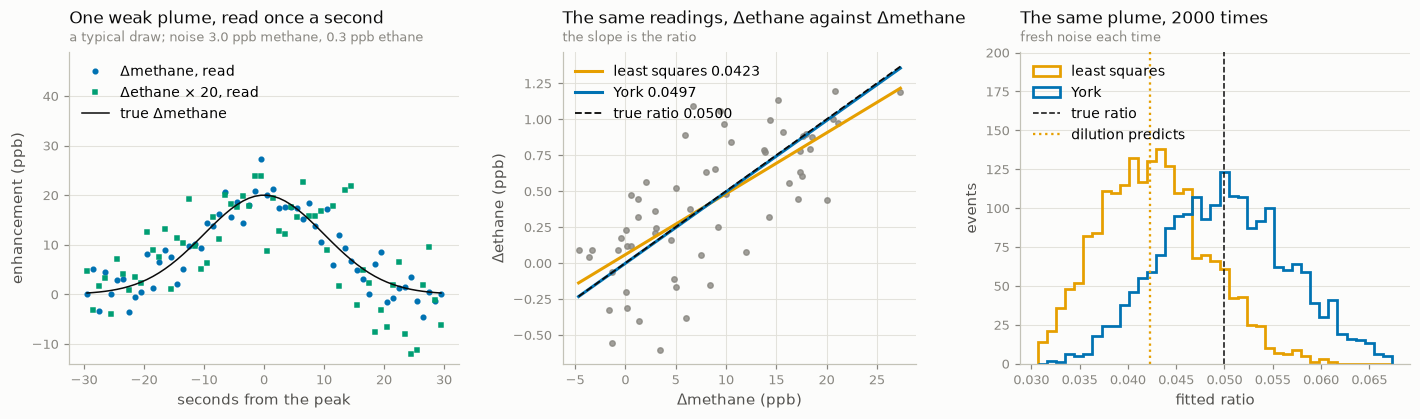

In [4]:
# Figure only.
fig, (ax_t, ax_s, ax_h) = plt.subplots(1, 3, figsize=(13, 3.9), width_ratios=[1.1, 1, 1.1])
t = np.arange(N_READINGS) - (N_READINGS - 1) / 2
gain = 1 / RATIO if RATIO else 1.0  # draw ethane on methane's scale

# (a) the event in time
ax_t.plot(t, x[first], "o", ms=3, color=C1, label="Δmethane, read")
ax_t.plot(t, gain * y[first], "s", ms=3, color=C3, label=f"Δethane × {gain:g}, read")
ax_t.plot(t, true_x, color=INK, lw=1, label="true Δmethane")
low, high = ax_t.get_ylim()
ax_t.set_ylim(low, high + 0.45 * (high - low))  # room for the legend
finish(
    ax_t,
    "One weak plume, read once a second",
    f"a typical draw; noise {SIGMA_CH4} ppb methane, {SIGMA_C2H6} ppb ethane",
    ylab="enhancement (ppb)",
    xlab="seconds from the peak",
    legend=True,
    loc="upper left",
)

# (b) the same readings on a 1:1 chart, with three lines
ax_s.plot(x[first], y[first], "o", ms=3.5, color=MUTED, alpha=0.8)
span = np.linspace(min(x[first].min(), 0), x[first].max(), 2)
ax_s.plot(
    span,
    by_ols.intercept[k] + by_ols.slope[k] * span,
    color=C2,
    lw=2,
    label=f"least squares {by_ols.slope[k]:.4f}",
)
ax_s.plot(
    span,
    by_york.intercept[k] + by_york.slope[k] * span,
    color=C1,
    lw=2,
    label=f"York {by_york.slope[k]:.4f}",
)
ax_s.plot(span, RATIO * span, "--", color=INK, lw=1.2, zorder=4, label=f"true ratio {RATIO:.4f}")
finish(
    ax_s,
    "The same readings, Δethane against Δmethane",
    "the slope is the ratio",
    ylab="Δethane (ppb)",
    xlab="Δmethane (ppb)",
    legend=True,
    loc="upper left",
    grid_axis="both",
)

# (c) many draws of the same plume
bins = np.linspace(*np.percentile(np.r_[by_ols.slope, by_york.slope[by_york.ok]], [0.5, 99.5]), 40)
counts_ols, *_ = ax_h.hist(
    by_ols.slope, bins, histtype="step", lw=1.8, color=C2, label="least squares"
)
counts_york, *_ = ax_h.hist(
    by_york.slope[by_york.ok], bins, histtype="step", lw=1.8, color=C1, label="York"
)
ax_h.set_ylim(0, 1.45 * max(counts_ols.max(), counts_york.max()))  # room for the legend
ax_h.axvline(RATIO, ls="--", color=INK, lw=1, label="true ratio")
ax_h.axvline(shrink * RATIO, ls=":", color=C2, lw=1.5, label="dilution predicts")
finish(
    ax_h,
    f"The same plume, {N_EVENTS} times",
    "fresh noise each time",
    ylab="events",
    xlab="fitted ratio",
    legend=True,
    loc="upper left",
)
fig.tight_layout()
plt.show()

**What to notice.** In the middle panel the two fitted lines pass through the
same cloud, and on one event the difference between them looks like noise.
The right panel says it is not: least squares lands, on average, exactly where
dilution predicts (the dotted line), and York lands on the truth. On a weak
plume this is a bias of tens of percent, the same direction every time, so it
does not average away over many events; it is the kind of error a campaign
mean inherits whole.

**What York needed to know.** The two σ's, one per gas, and nothing else. They
are the precisions to be declared in the manifest, and without them York fits
no line at all (it says so, `FitStatus.MISSING_SIGMA`, rather than guessing).
§4.3 and §4.5 of `METHODS.md` say what happens when they are declared at the
wrong scale.

2026-10-20 13:24:02 | WARNING  | tsara.ratios.estimators | York's slope did not settle in 1 of 2000 groups; they hold no line.


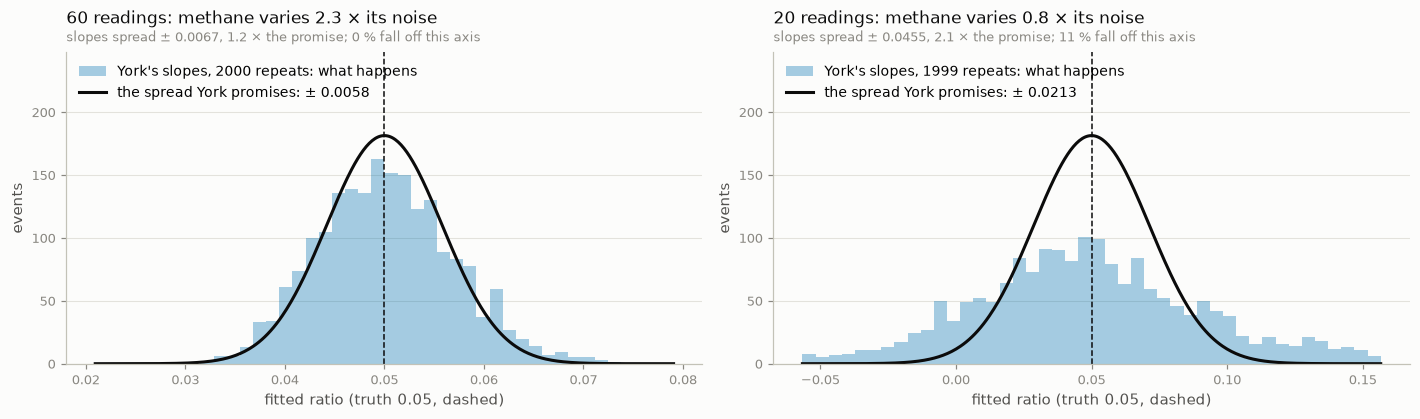

In [5]:
# Figure only: York's promised ± against how its slopes actually spread.
short_x, short_y, short_group, short_true = plume_events(
    n_events=N_EVENTS,
    n_readings=N_SHORT,
    peak=PEAK,
    width_s=WIDTH_S,
    ratio=RATIO,
    sigma_x=SIGMA_CH4,
    sigma_y=SIGMA_C2H6,
    seed=SEED,
)
by_york_short = york(short_x, short_y, SIGMA_CH4, SIGMA_C2H6, short_group)

fig, axes = plt.subplots(1, 2, figsize=(13, 3.9))
for ax, fit, n, truth in zip(
    axes, (by_york, by_york_short), (N_READINGS, N_SHORT), (true_x, short_true)
):
    slopes = fit.slope[fit.ok]
    promised = np.median(fit.slope_sigma[fit.ok])
    actual = 1.4826 * np.median(np.abs(slopes - np.median(slopes)))  # robust: wild misses happen
    lo, hi = RATIO - 5 * promised, RATIO + 5 * promised
    bins = np.linspace(lo, hi, 45)
    ax.hist(
        slopes[(slopes >= lo) & (slopes <= hi)],
        bins,
        color=C1,
        alpha=0.35,
        label=f"York's slopes, {slopes.size} repeats: what happens",
    )
    grid = np.linspace(lo, hi, 400)
    bell = np.exp(-0.5 * ((grid - RATIO) / promised) ** 2) / (promised * np.sqrt(2 * np.pi))
    ax.plot(
        grid,
        slopes.size * (bins[1] - bins[0]) * bell,
        color=INK,
        lw=2,
        label=f"the spread York promises: ± {promised:.4f}",
    )
    ax.axvline(RATIO, color=INK, ls="--", lw=1)
    off = np.mean((slopes < lo) | (slopes > hi))
    signal = np.std(truth) / SIGMA_CH4 if SIGMA_CH4 else np.inf
    ax.set_ylim(0, 1.3 * ax.get_ylim()[1])
    finish(
        ax,
        f"{n} readings: methane varies {signal:.1f} × its noise",
        f"slopes spread ± {actual:.4f}, {actual / promised:.1f} × the promise; "
        f"{100 * off:.0f} % fall off this axis",
        ylab="events",
        xlab=f"fitted ratio (truth {RATIO}, dashed)",
        legend=True,
        loc="upper left",
    )
fig.tight_layout()
plt.show()

York's ± is a promise about how far a repeat of the same event would land, and
the repeats above test it: at the default the slopes spread about 1.2 × wider
than promised, and on the shorter event, where methane varies less than its
noise, twice as wide with wild misses. The line stays right where there is
signal, but its ± is not to be trusted where there is little, and judging that
is 7c's (`METHODS.md` §4.5, Table 5).

**Try it**

* `SIGMA_CH4 = 0.0` — methane exact. The two lines are the same line, and both
  histograms sit on the truth: York with an exact x *is* least squares, and
  settles in one iteration.
* `PEAK = 100.0` — a strong plume. Dilution shrinks to under 1 %: least squares
  is nearly right, and York matters little. York earns its place on weak events.
* `SIGMA_C2H6 = 3.0` — ten times the ethane noise. Both histograms widen about
  tenfold and neither mean moves: noise on y costs precision, never bias.
* `N_READINGS = 10` — only the ten seconds around the peak, where true methane
  varies by a quarter of its noise. No line recovers a ratio from that: least
  squares reads near zero, York's slopes scatter without bound (median 0.014,
  mean far off, one fit that never settles) and its σ covers the truth only
  0.46 / 0.74 of the time. An event the reference gas barely moves in has no
  ratio to give, and York's own σ does not fully say so.

---
## 2. The ± is precision, not proof the line fits

York's ± answers one question: *if one straight line plus the declared noise
describes these points*, how precisely is its slope pinned down? It is worked
out from the declared σ's and how far methane swings. It does not look at how
well the points actually sit on the line. So an event that mixes two sources,
whose points no single line describes, can carry a ± just as tight as a clean
single-source event.

What does look is the **MSWD**: the scatter of the points about the line,
divided by the scatter the declared σ's predict. If one line plus the declared
noise explains the points, it is about 1. If something else adds scatter (a
second source, an understated σ), it is larger. How much larger counts as "too
large" depends on how many points there are: a true line's MSWD wanders
further from 1 on few points than on many, and the χ² distribution says
exactly how far. The **gate** below flags a fit whose MSWD a true line would
exceed only 1 % of the time.

The event: a gas puff (ethane/methane 0.05), then a landfill puff (no ethane),
two minutes read once a second. Beside it, the same methane from one source.

In [6]:
# ---- PARAMETERS (section 2) ----
RATIO_GAS = 0.05  # the gas puff's Δethane / Δmethane
RATIO_LANDFILL = 0.0  # the landfill puff's: a source with no ethane
PEAK_GAS = 20.0  # the gas puff's methane peak, ppb, a third of the way into the event
PEAK_LANDFILL = 25.0  # the landfill puff's, two thirds of the way in
N_READINGS = 120  # 1 s readings in the event; each puff lasts about a sixth of it
SIGMA_CH4 = 3.0  # methane noise per reading, ppb
SIGMA_C2H6 = 0.1  # ethane noise per reading, ppb
N_EVENTS = 2000  # repeats with fresh noise
GATE = 0.99  # flag a fit whose MSWD a true line would exceed only 1 - GATE of the time
SEED = 11

In [7]:
start_section("§2")
width = N_READINGS / 15
cases = {}
for name, landfill_ratio in (("one source", RATIO_GAS), ("mixed", RATIO_LANDFILL)):
    x, y, group, true_x, true_y = puff_events(
        n_events=N_EVENTS,
        n_readings=N_READINGS,
        puffs=[
            (N_READINGS / 3, PEAK_GAS, width, RATIO_GAS),
            (2 * N_READINGS / 3, PEAK_LANDFILL, width, landfill_ratio),
        ],
        sigma_x=SIGMA_CH4,
        sigma_y=SIGMA_C2H6,
        seed=SEED,
    )
    cases[name] = (x, y, group, york(x, y, SIGMA_CH4, SIGMA_C2H6, group))

# The gate: the MSWD a true line exceeds only 1 - GATE of the time, from χ² on n - 2.
dof = N_READINGS - 2
gate = chi2.ppf(GATE, dof) / dof
print(f"{N_EVENTS} repeats of each event, {N_READINGS} readings")
print(f"the {GATE:.0%} gate is MSWD {gate:.2f}")
print(f"  {'':11} {'median ratio':>13} {'median ±':>9} {'median MSWD':>12} {'above the gate':>15}")
for name, (*_, fit) in cases.items():
    ok = fit.ok
    print(
        f"  {name:11} {np.median(fit.slope[ok]):13.4f} {np.median(fit.slope_sigma[ok]):9.4f}"
        f" {np.median(fit.mswd[ok]):12.2f} {np.mean(fit.mswd[ok] > gate):15.1%}"
    )
print(f"  the sources' own ratios: {RATIO_GAS} and {RATIO_LANDFILL}")

print("\nWhere the gate sits depends on how many points the fit has:")
for n in (10, 30, 60, 120, 600):
    print(f"  {n:4} points: MSWD above {chi2.ppf(GATE, n - 2) / (n - 2):.2f}")

# --- checks -------------------------------------------------------------------
x, y, group, fit = cases["mixed"]
first = group == 0
b_ref, a_ref, _ = reference_york(x[first], y[first], SIGMA_CH4, SIGMA_C2H6)
weight = 1 / (SIGMA_C2H6**2 + b_ref**2 * SIGMA_CH4**2)
by_hand = np.sum(weight * (y[first] - a_ref - b_ref * x[first]) ** 2) / dof
check(
    "§2 York's MSWD is the weighted scatter about its line, written out by hand",
    np.isclose(fit.mswd[0], by_hand, rtol=1e-9),
    f"{fit.mswd[0]:.4f} vs {by_hand:.4f}",
)
single = cases["one source"][3]
signal = np.std(true_x) / SIGMA_CH4
if signal >= 1:
    # For a true line with the right σ's the MSWD is χ² on n - 2 over n - 2: mean 1,
    # standard deviation √(2 / (n - 2)), and above the gate 1 - GATE of the time.
    m = single.mswd[single.ok]
    tol = 4 * np.sqrt(2 / dof) / np.sqrt(m.size) + 0.02
    check(
        "§2 on single-source events the MSWD averages 1, as χ² says",
        abs(np.mean(m) - 1) <= tol,
        f"mean {np.mean(m):.3f}",
    )
    p = 1 - GATE
    tol = 4 * np.sqrt(p * (1 - p) / m.size) + 0.005
    check(
        f"§2 the gate flags single-source events about {p:.0%} of the time",
        abs(np.mean(m > gate) - p) <= tol,
        f"{np.mean(m > gate):.1%}",
    )
else:
    print("  (methane varies less than its noise here: no claim about the MSWD's spread)")

2000 repeats of each event, 120 readings
the 99% gate is MSWD 1.33
               median ratio  median ±  median MSWD  above the gate
  one source         0.0501    0.0020         0.99            0.5%
  mixed              0.0426    0.0022         5.35          100.0%
  the sources' own ratios: 0.05 and 0.0

Where the gate sits depends on how many points the fit has:
    10 points: MSWD above 2.51
    30 points: MSWD above 1.72
    60 points: MSWD above 1.48
   120 points: MSWD above 1.33
   600 points: MSWD above 1.14
  ✔ §2 York's MSWD is the weighted scatter about its line, written out by hand   [5.2759 vs 5.2759]
  ✔ §2 on single-source events the MSWD averages 1, as χ² says   [mean 0.997]
  ✔ §2 the gate flags single-source events about 1% of the time   [0.5%]


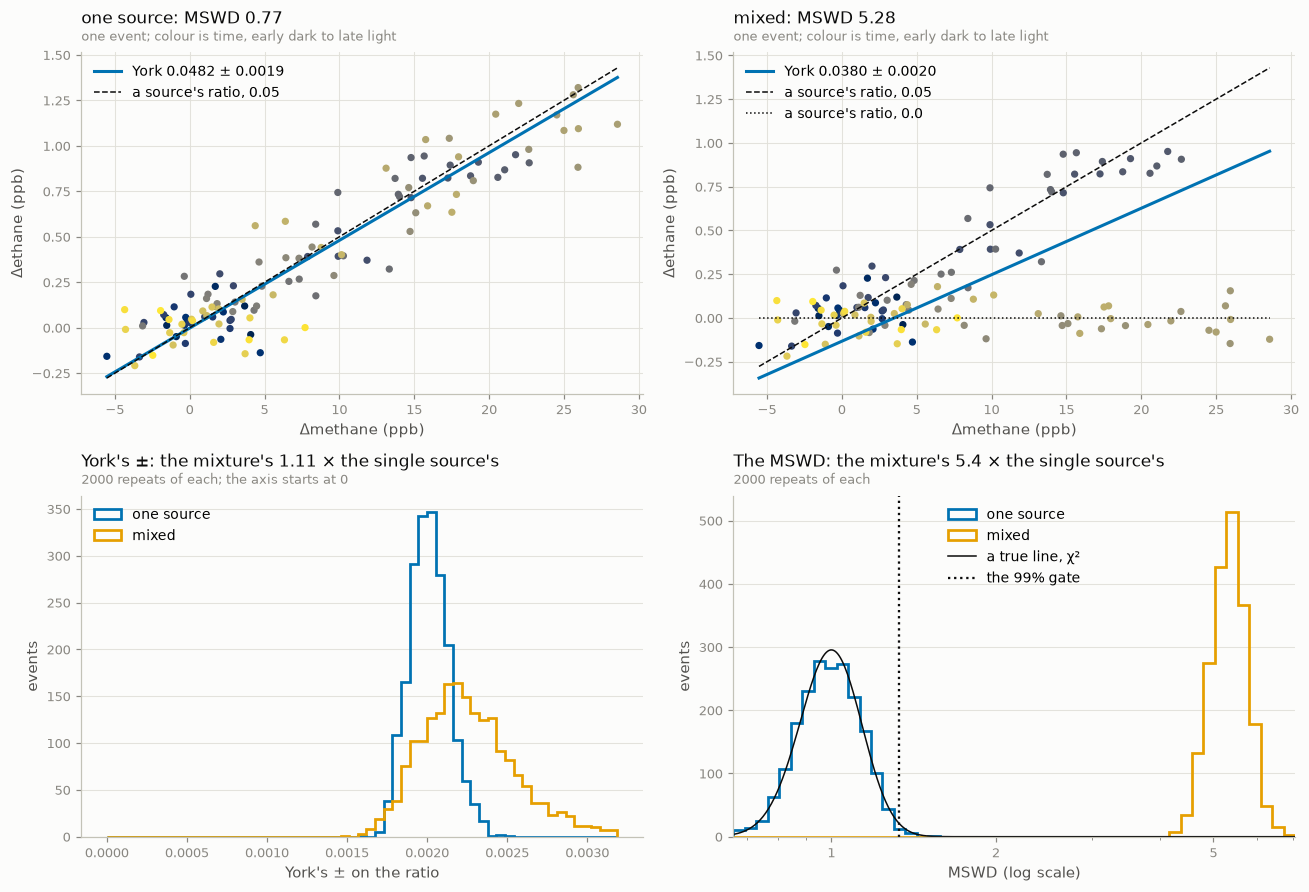

In [8]:
# Figure only.
fig, axes = plt.subplots(2, 2, figsize=(12, 8.2))
seconds = np.arange(N_READINGS)
for ax, name in zip(axes[0], ("one source", "mixed")):
    x, y, group, fit = cases[name]
    first = group == 0
    ax.scatter(x[first], y[first], c=seconds, cmap="cividis", s=14)
    span = np.linspace(min(x[first].min(), 0), x[first].max(), 2)
    ax.plot(
        span,
        fit.intercept[0] + fit.slope[0] * span,
        color=C1,
        lw=2,
        label=f"York {fit.slope[0]:.4f} ± {fit.slope_sigma[0]:.4f}",
    )
    for ratio, style in ((RATIO_GAS, "--"), (RATIO_LANDFILL, ":")):
        if name == "mixed" or ratio == RATIO_GAS:
            ax.plot(span, ratio * span, style, color=INK, lw=1, label=f"a source's ratio, {ratio}")
    finish(
        ax,
        f"{name}: MSWD {fit.mswd[0]:.2f}",
        "one event; colour is time, early dark to late light",
        ylab="Δethane (ppb)",
        xlab="Δmethane (ppb)",
        legend=True,
        loc="upper left",
        grid_axis="both",
    )

ax = axes[1, 0]
sigmas = np.r_[[cases[n][3].slope_sigma for n in cases]]
bins = np.linspace(0, np.nanpercentile(sigmas, 99.5), 60)  # from 0, to show the scale
for (name, (*_, fit)), colour in zip(cases.items(), (C1, C2)):
    ax.hist(fit.slope_sigma[fit.ok], bins, histtype="step", lw=1.8, color=colour, label=name)
wider = np.nanmedian(cases["mixed"][3].slope_sigma) / np.nanmedian(
    cases["one source"][3].slope_sigma
)
finish(
    ax,
    f"York's ±: the mixture's {wider:.2f} × the single source's",
    f"{N_EVENTS} repeats of each; the axis starts at 0",
    ylab="events",
    xlab="York's ± on the ratio",
    legend=True,
    loc="upper left",
)

ax = axes[1, 1]
values = np.r_[[cases[n][3].mswd for n in cases]]
bins = np.geomspace(max(np.nanmin(values), 1e-2), np.nanmax(values), 50)
for (name, (*_, fit)), colour in zip(cases.items(), (C1, C2)):
    ax.hist(fit.mswd[fit.ok], bins, histtype="step", lw=1.8, color=colour, label=name)
grid = np.geomspace(bins[0], bins[-1], 400)
density = chi2.pdf(grid * dof, dof) * dof  # a true line's MSWD, per unit MSWD
ax.plot(
    grid,
    density * N_EVENTS * np.diff(np.log(bins)).mean() * grid,
    color=INK,
    lw=1,
    label="a true line, χ²",
)
ax.axvline(gate, color=INK, ls=":", lw=1.5, label=f"the {GATE:.0%} gate")
ax.set_xscale("log")
ax.set_xticks([0.5, 1, 2, 5, 10, 20])
ax.set_xticklabels(["0.5", "1", "2", "5", "10", "20"])
ax.tick_params(axis="x", which="minor", labelbottom=False)
ax.set_xlim(bins[0], bins[-1])
louder = np.nanmedian(cases["mixed"][3].mswd) / np.nanmedian(cases["one source"][3].mswd)
finish(
    ax,
    f"The MSWD: the mixture's {louder:.1f} × the single source's",
    f"{N_EVENTS} repeats of each",
    ylab="events",
    xlab="MSWD (log scale)",
    legend=True,
    loc="upper center",
)
fig.tight_layout()
plt.show()

**What to notice.** Top row: the single-source points lie along one line;
the mixed event's points, coloured by time, run along the gas line first and
then fall back along the landfill line, and York threads a compromise between
them. Bottom left: York's ± is barely wider for the mixture. Bottom right:
its MSWD is several times larger; every mixed event lies far beyond the gate,
while the single-source events follow χ², as a true line must. The ± says how precise the
slope is if one line is the right description; the MSWD says whether it is.

**Try it**

* `RATIO_LANDFILL = 0.05` — the "landfill" now carries the gas ratio, so both
  events are single-source. The two histograms lie on each other and the gate
  flags about 1 % of each.
* `SIGMA_C2H6 = 0.03` — a quieter ethane. The mixed event's slope reads about
  0.077, above *both* sources' ratios, and its ± (about 0.005) presents that as
  a precise measurement five of its σ's from the gas ratio. A mixture's slope
  depends even on the declared noise: it is not the ratio of anything. Only
  the MSWD (about 6.7) says so.
* `SIGMA_C2H6 = 0.3` — a noisier ethane. The mixture's MSWD falls to about 1.8,
  yet still lies above the gate in nearly every event: on 120 points, 1.8 is
  far outside what a true line does. Its slope now reads about 0.019.
* `N_READINGS = 30` — a shorter event. The gate rises from 1.33 to 1.72,
  because a true line's MSWD wanders further on fewer points; the mixtures
  still clear it here, by a smaller margin.

---
## 3. When the declared σ's are wrong

York is told each gas's σ, and §1 and §2 told it the truth. A real manifest
will not always manage that. There are two different ways to get them wrong,
and they do different damage.

**A wrong common scale**, both σ's too large or too small by the same factor.
The line does not move: York weighs points against each other, and a common
factor cancels. Its ± scales with the declared σ's, so it is wrong by that
factor, and the MSWD sees it: declare both σ's twice too large and the MSWD
reads about ¼. Widening the ± by √MSWD undoes the error whatever the factor,
which is why, with that widening, only the *ratio* of the two precisions has
to be right.

**A wrong ratio** between the gases. York's line sits between two extremes:
least squares, which assumes methane exact, and the reverse fit, which assumes
ethane exact. The ratio of the two σ's decides where. Declare methane noisier
than it is (or ethane quieter, which is the same thing) and the line tilts
toward the reverse fit; the other way, toward least squares and its dilution.
This moves the slope itself, more on a weak plume than a strong one, and no
widening of the ± repairs it.

In [9]:
# ---- PARAMETERS (section 3) ----
RATIO = 0.05  # the source's true Δethane / Δmethane
PEAK = 60.0  # a strong plume: with the right σ's York's ± is honest here (§1 has the weak case)
PEAK_WEAK = 20.0  # §1's weak plume, for the second panel
WIDTH_S = 10.0  # the plume's standard deviation in time, s
N_READINGS = 60  # 1 s readings, centred on the peak
SIGMA_CH4 = 3.0  # the noise the methane readings really carry, ppb
SIGMA_C2H6 = 0.3  # and the ethane readings
SCALES = (0.25, 0.5, 1.0, 2.0, 4.0)  # declared σ ÷ true σ
N_EVENTS = 2000
SEED = 5

In [10]:
start_section("§3")
draws = {}
for peak in (PEAK, PEAK_WEAK):
    draws[peak] = plume_events(
        n_events=N_EVENTS,
        n_readings=N_READINGS,
        peak=peak,
        width_s=WIDTH_S,
        ratio=RATIO,
        sigma_x=SIGMA_CH4,
        sigma_y=SIGMA_C2H6,
        seed=SEED,
    )


def covered(fit, widen="none"):
    """Return the share of events whose true ratio lies within ±1 of the fit's (widened) σ."""
    sigma = fit.slope_sigma
    if widen == "sqrt":
        sigma = sigma * np.sqrt(fit.mswd)
    elif widen == "sqrt max":
        sigma = sigma * np.sqrt(np.maximum(1.0, fit.mswd))
    return float(np.mean(np.abs(fit.slope[fit.ok] - RATIO) <= sigma[fit.ok]))


# (a) both σ's declared k times their true size, on the strong plume
x, y, group, true_x = draws[PEAK]
by_scale = {k: york(x, y, k * SIGMA_CH4, k * SIGMA_C2H6, group) for k in SCALES}
print(f"Both σ's declared k × their true size ({N_EVENTS} strong plumes). Share of events")
print("whose true ratio lies within ±1σ, nominally 0.68:")
print(f"  {'k':>5} {'median MSWD':>12} {'York ±':>8} {'± × √MSWD':>11} {'± × √max(1, MSWD)':>19}")
for k, fit in by_scale.items():
    print(
        f"  {k:5g} {np.median(fit.mswd[fit.ok]):12.3f} {covered(fit):8.3f}"
        f" {covered(fit, 'sqrt'):11.3f} {covered(fit, 'sqrt max'):19.3f}"
    )

# (b) only methane's σ declared k times its true size, ethane's right
by_ratio = {
    peak: {k: york(*draws[peak][:2], k * SIGMA_CH4, SIGMA_C2H6, draws[peak][2]) for k in SCALES}
    for peak in (PEAK, PEAK_WEAK)
}
print("\nOnly methane's σ declared k × its true size. York's median ratio (truth", RATIO, "):")
print(f"  {'k':>5}" + "".join(f"   peak {peak:g} ppb" for peak in by_ratio))
for k in SCALES:
    print(f"  {k:5g}" + "".join(f" {np.median(by_ratio[p][k].slope):15.4f}" for p in by_ratio))
for peak in by_ratio:
    least = ols(*draws[peak][:2], group=draws[peak][2])
    print(f"  least squares, peak {peak:g} ppb: {np.median(least.slope):.4f}")

# --- checks -------------------------------------------------------------------
right = by_scale.get(1.0) or york(x, y, SIGMA_CH4, SIGMA_C2H6, group)
same_line = all(np.allclose(f.slope, right.slope, rtol=1e-10) for f in by_scale.values())
scaled = all(
    np.allclose(f.mswd * k**2, right.mswd, rtol=1e-9)
    and np.allclose(
        f.slope_sigma * np.sqrt(f.mswd), right.slope_sigma * np.sqrt(right.mswd), rtol=1e-9
    )
    for k, f in by_scale.items()
)
check("§3 a common scale on both σ's leaves every event's line where it was", same_line)
check("§3 a common scale k divides the MSWD by k² and leaves σ_b·√MSWD unchanged", scaled)
k = SCALES[-1]
methane_up = york(x, y, k * SIGMA_CH4, SIGMA_C2H6, group)
ethane_down = york(x, y, SIGMA_CH4, SIGMA_C2H6 / k, group)
check(
    "§3 methane's σ × k moves the line exactly as ethane's σ ÷ k: only the ratio counts",
    np.allclose(methane_up.slope, ethane_down.slope, rtol=1e-10),
)
signal = np.std(true_x) / SIGMA_CH4
if signal >= 5:
    # A right ± covers 68.3 %; allow four binomial standard errors and 3 points of the
    # first-order formula's own shortfall (§1, METHODS §4.5 Table 5).
    tol = 4 * np.sqrt(0.683 * 0.317 / N_EVENTS) + 0.03
    check(
        "§3 with the right σ's on a strong plume, York's ± covers the truth 68 % of the time",
        abs(covered(right) - 0.683) <= tol,
        f"{covered(right):.3f}",
    )

Both σ's declared k × their true size (2000 strong plumes). Share of events
whose true ratio lies within ±1σ, nominally 0.68:
      k  median MSWD   York ±   ± × √MSWD   ± × √max(1, MSWD)
   0.25       15.977    0.194       0.665               0.665
    0.5        3.994    0.376       0.665               0.665
      1        0.999    0.677       0.665               0.690
      2        0.250    0.949       0.665               0.949
      4        0.062    1.000       0.665               1.000



Only methane's σ declared k × its true size. York's median ratio (truth 0.05 ):
      k   peak 60 ppb   peak 20 ppb
   0.25          0.0491          0.0428
    0.5          0.0493          0.0443
      1          0.0500          0.0500
      2          0.0516          0.0653
      4          0.0531          0.0791
  least squares, peak 60 ppb: 0.0490
  least squares, peak 20 ppb: 0.0423
  ✔ §3 a common scale on both σ's leaves every event's line where it was
  ✔ §3 a common scale k divides the MSWD by k² and leaves σ_b·√MSWD unchanged
  ✔ §3 methane's σ × k moves the line exactly as ethane's σ ÷ k: only the ratio counts
  ✔ §3 with the right σ's on a strong plume, York's ± covers the truth 68 % of the time   [0.677]


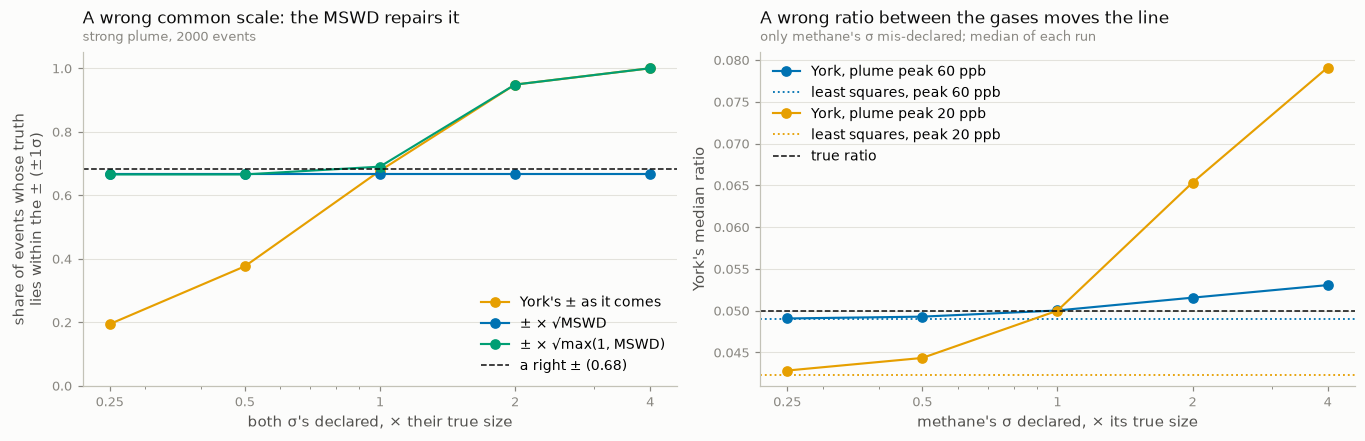

In [11]:
# Figure only.
fig, (ax_a, ax_b) = plt.subplots(1, 2, figsize=(12.5, 4.1))
ks = np.array(SCALES)
for widen, colour, label in (
    ("none", C2, "York's ± as it comes"),
    ("sqrt", C1, "± × √MSWD"),
    ("sqrt max", C3, "± × √max(1, MSWD)"),
):
    ax_a.plot(ks, [covered(by_scale[k], widen) for k in SCALES], "o-", color=colour, label=label)
ax_a.axhline(0.683, color=INK, ls="--", lw=1, label="a right ± (0.68)")
ax_a.set_xscale("log")
ax_a.set_xticks(ks)
ax_a.set_xticklabels([f"{k:g}" for k in ks])
ax_a.tick_params(axis="x", which="minor", labelbottom=False)
ax_a.set_ylim(0, 1.05)
finish(
    ax_a,
    "A wrong common scale: the MSWD repairs it",
    f"strong plume, {N_EVENTS} events",
    ylab="share of events whose truth\nlies within the ± (±1σ)",
    xlab="both σ's declared, × their true size",
    legend=True,
    loc="lower right",
)

for peak, colour in ((PEAK, C1), (PEAK_WEAK, C2)):
    ax_b.plot(
        ks,
        [np.median(by_ratio[peak][k].slope) for k in SCALES],
        "o-",
        color=colour,
        label=f"York, plume peak {peak:g} ppb",
    )
    ax_b.axhline(
        np.median(ols(*draws[peak][:2], group=draws[peak][2]).slope),
        color=colour,
        ls=":",
        lw=1.2,
        label=f"least squares, peak {peak:g} ppb",
    )
ax_b.axhline(RATIO, color=INK, ls="--", lw=1, label="true ratio")
ax_b.set_xscale("log")
ax_b.set_xticks(ks)
ax_b.set_xticklabels([f"{k:g}" for k in ks])
ax_b.tick_params(axis="x", which="minor", labelbottom=False)
finish(
    ax_b,
    "A wrong ratio between the gases moves the line",
    "only methane's σ mis-declared; median of each run",
    ylab="York's median ratio",
    xlab="methane's σ declared, × its true size",
    legend=True,
    loc="upper left",
)
fig.tight_layout()
plt.show()

**What to notice.** Left: York's ± as it comes is right only at the right
scale, too tight below it and too loose above; widened by √MSWD it covers
about 68 % at every scale; widened only when the MSWD exceeds 1, it repairs an
understatement and keeps an overstatement (the safe side). Right: with
methane's σ declared too large, the line tilts toward the reverse fit and
reads high; too small, it slides toward least squares and reads low. On the
strong plume that is a few percent; on the weak one, tens of percent.

**What this means for declaring precisions.** With the ± widened by √MSWD,
the absolute size of the two σ's stops mattering and their *ratio* is what
must be right, because it decides where the line sits. That ratio may also be
the easier thing to pin down: where both gases come from one cell and one
spectrum, as on an Aeris, the scatter of readings while the analyzer breathes
a steady gas (a cylinder, or zero air) measures both σ's at once. Widening by √MSWD has a price, though: it treats all excess scatter as a
mis-scaled σ, so a mixture (§2) would come out with a wide ± instead of being
flagged. Which rule the ratio stage uses is decided in 7c.

**Try it**

* `PEAK_WEAK = 40.0` — a plume twice as tall. The weak curve flattens toward
  the strong one: the declared ratio matters less where methane swings well
  above its noise.
* `SCALES = (0.8, 0.9, 1.0, 1.1, 1.25)` — mis-declarations of 10–25 %. Even
  these move the weak plume's ratio by several percent, in the direction of
  the error.

---
## 4. When errors persist from reading to reading

York assumes each reading's noise is new: knowing one reading's error says
nothing about the next. An analyzer whose cell takes several seconds to flush
breaks that. Each reading shares part of its error with its neighbours, and
the noise wanders in slow runs instead of jumping about. The σ of each reading
is unchanged; what changes is how many *independent* pieces of information
sixty readings hold.

Two things follow. A run of noise lying along the plume tilts the line, and
York, counting sixty independent readings, promises a ± far tighter than the
slopes' real spread. And the MSWD cannot see it: each reading still scatters
by its declared σ, and a slow run is partly absorbed by the fitted line, so
the MSWD reads 1 or *below*. The gate of §2 passes these events, and widening
by √MSWD makes the ± tighter still.

**Persistence is the decorrelation timescale τ, seen from one reading to the
next.** For readings Δt apart, ρ = e^(−Δt/τ): at 1 s, ρ 0.5 is τ 1.4 s, ρ 0.7
is τ 2.8 s, ρ 0.9 is τ 9.5 s. It sits between TSARA's two kinds of error:
*random* is new at every reading and averages down as 1/√N; *systematic* is the
same at every reading and does not average down at all; random with a declared
τ (the manifest's `decorrelation_timescale`) averages down as 1/√N_eff, with
N_eff the number of independent readings N correlated ones are worth
(`METHODS.md` §3.4). TSARA's averaging already uses it. York, as built in 7a,
does not: it takes one σ per point and assumes the points independent.

Below, York as it comes, and two ways to give it the τ, both through TSARA's
own N_eff: **widen** its ± by √(N / N_eff) over the event, or **average** the
readings into longer means first, each mean's σ set by N_eff, and fit those.
For a slope through a smooth plume the factor York's ± falls short by is about
√((1 + ρ)/(1 − ρ)), the same factor N_eff gives a long mean.

In [12]:
# ---- PARAMETERS (section 4) ----
RATIO = 0.05  # the source's true Δethane / Δmethane
PEAK = 60.0  # a strong plume, so that only the persistence is wrong (§3)
WIDTH_S = 10.0  # the plume's standard deviation in time, s
N_READINGS = 60  # 1 s readings, centred on the peak
SIGMA_CH4 = 3.0  # methane noise per reading, ppb: declared exactly
SIGMA_C2H6 = 0.3  # ethane noise per reading, ppb: declared exactly
RHOS = (0.0, 0.3, 0.5, 0.7, 0.9)  # persistence values for the right-hand panel
RHO_DRAWN = 0.7  # the persistence the left-hand panel draws
MEAN_S = 10  # the second remedy fits means of this many 1 s readings
N_EVENTS = 2000
SEED = 5

In [13]:
start_section("§4")
dof = N_READINGS - 2
gate = chi2.ppf(0.99, dof) / dof
rows = {}
for rho in RHOS:
    x, y, group, true_x = plume_events(
        n_events=N_EVENTS,
        n_readings=N_READINGS,
        peak=PEAK,
        width_s=WIDTH_S,
        ratio=RATIO,
        sigma_x=SIGMA_CH4,
        sigma_y=SIGMA_C2H6,
        seed=SEED,
        rho=rho,
    )
    fit = york(x, y, SIGMA_CH4, SIGMA_C2H6, group)
    tau = -1.0 / np.log(rho) if rho > 0 else None  # τ in seconds, from ρ at 1 s
    # Remedy 1: widen York's ± by √(N / N_eff) over the event's readings.
    n_eff = float(np.asarray(n_effective(N_READINGS, 1.0, tau)).item()) if tau else N_READINGS
    widened = fit.slope_sigma * np.sqrt(N_READINGS / n_eff)
    # Remedy 2: fit means of MEAN_S readings, each mean's σ set by N_eff over it.
    n_means = N_READINGS // MEAN_S
    keep = np.arange(N_READINGS * N_EVENTS).reshape(N_EVENTS, N_READINGS)[:, : n_means * MEAN_S]
    x_mean = x[keep].reshape(N_EVENTS, n_means, MEAN_S).mean(axis=2).ravel()
    y_mean = y[keep].reshape(N_EVENTS, n_means, MEAN_S).mean(axis=2).ravel()
    n_eff_mean = float(np.asarray(n_effective(MEAN_S, 1.0, tau)).item()) if tau else MEAN_S
    on_means = york(
        x_mean,
        y_mean,
        SIGMA_CH4 / np.sqrt(n_eff_mean),
        SIGMA_C2H6 / np.sqrt(n_eff_mean),
        np.repeat(np.arange(N_EVENTS), n_means),
    )

    def honesty(slopes, sigma):
        """Return the slopes' actual spread ÷ the promised σ (1 is honest), robustly."""
        actual = 1.4826 * np.median(np.abs(slopes - np.median(slopes)))
        return actual / np.median(sigma)

    slopes = fit.slope[fit.ok]
    rows[rho] = {
        "τ (s)": tau if tau else 0.0,
        "median ratio": np.median(slopes),
        "as it comes": honesty(slopes, fit.slope_sigma[fit.ok]),
        "widened": honesty(slopes, widened[fit.ok]),
        f"on {MEAN_S} s means": honesty(
            on_means.slope[on_means.ok], on_means.slope_sigma[on_means.ok]
        ),
        "textbook factor": np.sqrt((1 + rho) / (1 - rho)),
        "median MSWD": np.median(fit.mswd[fit.ok]),
        "above the gate": np.mean(fit.mswd[fit.ok] > gate),
        "n_eff": n_eff,
    }
print(f"{N_EVENTS} strong plumes per row, σ's declared exactly; 99 % gate {gate:.2f}.")
print("Columns 3-5: the slopes' actual spread ÷ York's ± (1 is honest).")
shown = [name for name in next(iter(rows.values())) if name != "n_eff"]
print(f"  {'ρ':>4} " + " ".join(f"{name:>15}" for name in shown))
for rho, row in rows.items():
    print(f"  {rho:4g} " + " ".join(f"{row[name]:15.3f}" for name in shown))

# --- checks -------------------------------------------------------------------
# For a fit of a true line with the right σ's, the MSWD's median sits just under 1
# (χ²'s median); persistence can only lower it, never raise it.
ceiling = chi2.median(dof) / dof + 4 * np.sqrt(2 / dof) / np.sqrt(N_EVENTS)
check(
    "§4 persistent noise never raises the MSWD: the gate cannot see it",
    all(row["median MSWD"] <= ceiling for rho, row in rows.items() if rho >= 0),
    ", ".join(f"ρ {rho:g}: {row['median MSWD']:.2f}" for rho, row in rows.items()),
)
persistent = [rho for rho in RHOS if rho >= 0.3]
if persistent:
    check(
        "§4 with persistence of 0.3 or more, York's ± is more than 10 % too tight",
        all(rows[rho]["as it comes"] > 1.1 for rho in persistent),
        ", ".join(f"ρ {rho:g}: {rows[rho]['as it comes']:.2f}" for rho in persistent),
    )
check(
    "§4 persistence does not bias the ratio: York's median stays on the truth",
    all(abs(row["median ratio"] - RATIO) <= 0.02 * RATIO for row in rows.values()),
)
# TSARA's N_eff against the AR(1) double sum, written out from METHODS §3.4:
# N_eff = N² / (N + 2 Σ_k (N − k) ρ^k).
lags = np.arange(1, N_READINGS)
by_hand = {
    rho: N_READINGS**2 / (N_READINGS + 2 * np.sum((N_READINGS - lags) * rho**lags)) for rho in rows
}
check(
    "§4 TSARA's N_eff is the AR(1) double sum written out",
    all(np.isclose(rows[rho]["n_eff"], by_hand[rho], rtol=1e-10) for rho in rows),
)
check(
    "§4 widened by √(N / N_eff), York's ± is never more than 10 % too tight",
    all(row["widened"] <= 1.1 for row in rows.values()),
    ", ".join(f"ρ {rho:g}: {row['widened']:.2f}" for rho, row in rows.items()),
)
check(
    f"§4 fitting {MEAN_S} s means never leaves the ± tighter than fitting the readings",
    all(row[f"on {MEAN_S} s means"] <= row["as it comes"] + 0.05 for row in rows.values()),
)

2000 strong plumes per row, σ's declared exactly; 99 % gate 1.48.
Columns 3-5: the slopes' actual spread ÷ York's ± (1 is honest).
     ρ           τ (s)    median ratio     as it comes         widened   on 10 s means textbook factor     median MSWD  above the gate
     0           0.000           0.050           1.010           1.010           1.026           1.000           0.999           0.010
   0.3           0.831           0.050           1.378           1.017           1.023           1.363           0.964           0.009
   0.5           1.443           0.050           1.725           1.007           1.040           1.732           0.915           0.015
   0.7           2.804           0.050           2.261           0.972           1.073           2.380           0.818           0.025
   0.9           9.491           0.050           2.924           0.731           1.057           4.359           0.534           0.024
  ✔ §4 persistent noise never raises the MSWD: the gate can

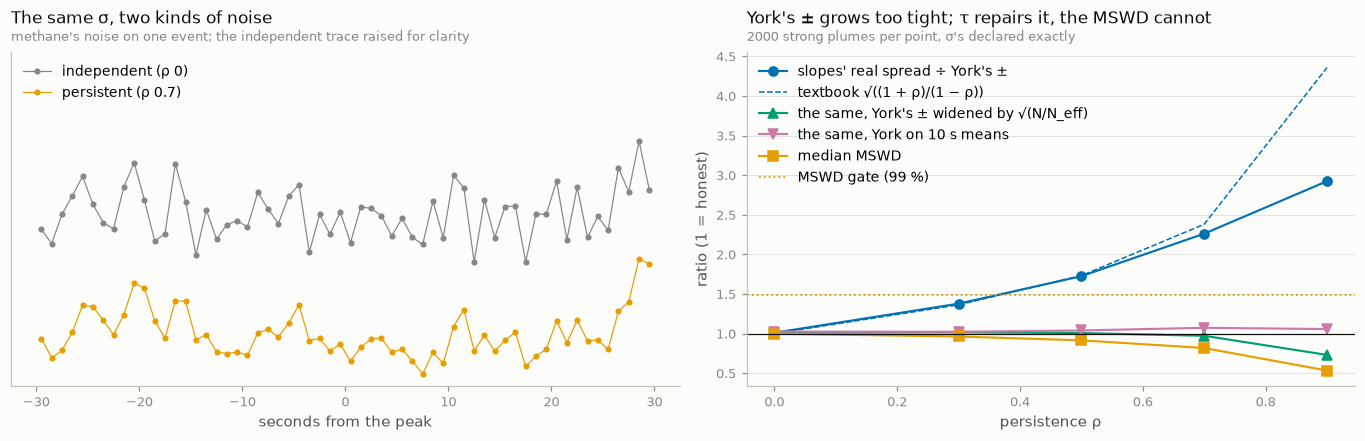

In [14]:
# Figure only.
fig, (ax_a, ax_b) = plt.subplots(1, 2, figsize=(12.5, 4.1), width_ratios=[1.1, 1])
rng = np.random.default_rng(SEED)
fresh = rng.standard_normal(N_READINGS)
runs = fresh.copy()
for i in range(1, N_READINGS):
    runs[i] = RHO_DRAWN * runs[i - 1] + np.sqrt(1 - RHO_DRAWN**2) * fresh[i]
t = np.arange(N_READINGS) - (N_READINGS - 1) / 2
ax_a.plot(
    t, SIGMA_CH4 * fresh + 4 * SIGMA_CH4, "o-", ms=3, lw=0.8, color=MUTED, label="independent (ρ 0)"
)
ax_a.plot(t, SIGMA_CH4 * runs, "o-", ms=3, lw=0.8, color=C2, label=f"persistent (ρ {RHO_DRAWN:g})")
ax_a.set_yticks([])
finish(
    ax_a,
    "The same σ, two kinds of noise",
    "methane's noise on one event; the independent trace raised for clarity",
    xlab="seconds from the peak",
    legend=True,
    loc="upper left",
)
low, high = ax_a.get_ylim()
ax_a.set_ylim(low, high + 0.3 * (high - low))

rhos = np.array(list(rows))
ax_b.plot(
    rhos,
    [rows[r]["as it comes"] for r in rows],
    "o-",
    color=C1,
    label="slopes' real spread ÷ York's ±",
)
ax_b.plot(
    rhos,
    [rows[r]["textbook factor"] for r in rows],
    "--",
    color=C1,
    lw=1,
    label="textbook √((1 + ρ)/(1 − ρ))",
)
ax_b.plot(
    rhos,
    [rows[r]["widened"] for r in rows],
    "^-",
    color=C3,
    label="the same, York's ± widened by √(N/N_eff)",
)
ax_b.plot(
    rhos,
    [rows[r][f"on {MEAN_S} s means"] for r in rows],
    "v-",
    color=C4,
    label=f"the same, York on {MEAN_S} s means",
)
ax_b.plot(rhos, [rows[r]["median MSWD"] for r in rows], "s-", color=C2, label="median MSWD")
ax_b.axhline(1, color=INK, lw=0.8)
ax_b.axhline(gate, color=C2, ls=":", lw=1.2, label="MSWD gate (99 %)")
finish(
    ax_b,
    "York's ± grows too tight; τ repairs it, the MSWD cannot",
    f"{N_EVENTS} strong plumes per point, σ's declared exactly",
    ylab="ratio (1 = honest)",
    xlab="persistence ρ",
    legend=True,
    loc="upper left",
)
fig.tight_layout()
plt.show()

**What to notice.** Left: the two traces have the same σ, but the persistent
one wanders in runs. Right: York's ± as it comes falls further behind the
slopes' real spread as ρ grows, close to the textbook factor until the runs
grow long beside the event, and the MSWD never rises to meet it: nothing in a
single fit reveals persistence. Given τ, both remedies bring the ± back:
widening is honest up to τ ≈ 3 s here and errs on the safe side beyond it;
fitting 10 s means comes within about 7 % on this one-minute plume (the first
Try it shows why that is partly luck). Neither moves the ratio.

**What this means for 7c, and for the manifest.** The mechanism is in place
(the manifest's `decorrelation_timescale`, TSARA's N_eff, and since the
2026-10-19 fix the enhancement carries τ); what is missing is twofold. The
ratio stage must apply one of these remedies, which is 7c's to choose
(`METHODS.md` §4.5, Table 7), and the τ must be declared, which no file in the
archive does yet. It can be measured where the precision is: while an analyzer
breathes a steady gas, the correlation between consecutive readings is ρ, and
τ = −Δt / ln ρ.

**Try it**

* `N_READINGS = 240` and `WIDTH_S = 40.0` — a plume four times as long, so the
  runs are short beside it. At ρ 0.9 the real spread approaches the textbook
  factor (about 4 against 4.4). The widening stays honest (0.93), but 10 s
  means fall 1.46 × behind: at τ 9.5 s they are not long enough, and the event
  is now long enough to show it. Widening is the more robust remedy.
* `RHOS = (0.0, 0.1, 0.2, 0.3)` — mild persistence. Already at ρ 0.2 the real
  spread is a quarter wider than York's ±, and the MSWD has not moved.
* `MEAN_S = 5` — shorter means. They help, but not enough at the larger ρ:
  still 30–40 % too tight at ρ 0.7 and 0.9, where their neighbours share
  error.

---
# Phase 7b: what an event is

Sections 1–4 fit a line through a stretch of readings. Sections 5–8 are about
*which* stretches. The events stage (Phase 6, notebook 06) reports **events**:
intervals where an enhancement rises a set number of clean spreads above
plume-free air. It does so at every **sweep point**: every baseline window ×
quantile × entry × exit. With the example sweep that is 3 × 3 × 3 × 3 = 81
points, so one plume can appear as dozens of events. Before a ratio can be fitted
to "a plume", someone has to say which of those events are the same thing. That
is a **candidate**: for one variable at one window, the events across
quantile, entry and exit that share a peak (`src/tsara/events/candidates.py`,
`METHODS.md` §6.8). It is a description of what the sweep saw, not a verdict
that a plume is there.

These sections run on manufactured air through the whole chain: the baseline
state, the events, the catalog and the candidates, exactly as a campaign
would. The generator records every plume it injected, so each candidate can be
scored against the truth.

---
## 5. One window, many views: what the sweep sees

Fix one baseline window. The other three sweep dimensions (quantile, entry and
exit) each change the events in their own way, and the grouping rule rests on
how. Each of the three facts below is drawn on one short stretch and then
checked over the whole record.

- **Entry only removes events.** The detector first finds runs of readings
  above *exit*, bridges short dips, and only then asks whether a run reaches
  *entry* (`find_events` in `src/tsara/events/hysteresis.py`). So at a fixed
  quantile and exit, the events at entry 4 are exactly the events at entry 3
  whose peak z reaches 4, interval for interval. Being found again at a higher
  entry and being tall are one piece of evidence, not two.
- **Exit nests.** A run above exit 2 is also above exit 1, so every event at a
  higher exit lies inside one event at the lower exit. Lowering the exit merges
  neighbours into one event, which peaks on the tallest of them.
- **Quantile moves things a little.** Another quantile is another baseline, a
  little higher or lower, so the events shift and stretch but mostly stay the
  same plumes.

In [15]:
# ---- PARAMETERS (section 5) ----
SEED = 5  # the landfill recipe's seed (notebook 06): which plumes the generator draws
DURATION = "6h"  # the record's length
WINDOW = 120.0  # the baseline window the figure looks at, s: 120, 600 or 3600
PAD_S = 90  # seconds shown either side of each column's event

21,600 readings over 6.0 h; 4,176 events at 81 sweep points


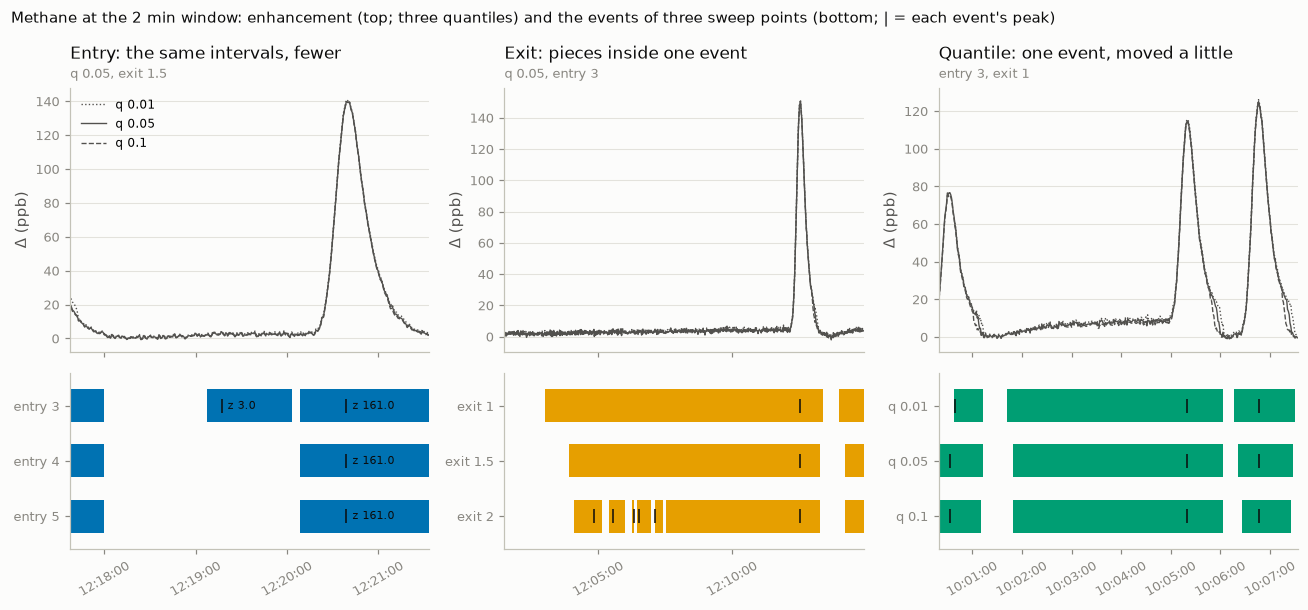

In [16]:
start_section("§5")
run = chain("landfill", seed=SEED, duration=DURATION)
cat = run.catalog
n_points = cat.groupby(
    ["baseline_window", "baseline_quantile", "enter_multiple", "exit_multiple"]
).ngroups
readings = run.stream.sizes["time"]
print(
    f"{readings:,} readings over {run.hours:.1f} h; {len(cat):,} events at {n_points} sweep points"
)

at = cat[cat.baseline_window == WINDOW]
base = at[(at.baseline_quantile == 0.05) & (at.enter_multiple == 3.0)]
x1, x2 = base[base.exit_multiple == 1.0], base[base.exit_multiple == 2.0]

# Each column draws its own event, a clear one on the record for its fact:
# entry, the lowest event at entry 3 at any quantile and exit (gone at entry 4
# or 5 when its peak z is below them); exit, the event at exit 1 that exit 2
# splits into the most pieces (the shortest of those); quantile, an event at
# q 0.05 whose partner at q 0.01 starts a typical distance away (the 75th
# percentile of the shifts that are not zero).
entry_event = at[at.enter_multiple == 3.0].sort_values("peak_z").iloc[0]
pieces = np.array(
    [int(holds(r.start_time, r.end_time, x2.peak_time).sum()) for _, r in x1.iterrows()]
)
splitting = x1[pieces == pieces.max()]
exit_event = splitting.sort_values("duration_s").iloc[0]
q01 = at[(at.baseline_quantile == 0.01) & (at.enter_multiple == 3.0) & (at.exit_multiple == 1.0)]
shift = []
for _, r in x1.iterrows():
    partner = q01[
        holds(q01.start_time, q01.end_time, r.peak_time)
        & holds(r.start_time, r.end_time, q01.peak_time)
    ]
    shift.append(
        abs((partner.start_time.iloc[0] - r.start_time).total_seconds()) if len(partner) else -1.0
    )
shift = np.array(shift)
moved = np.flatnonzero(shift > 0)
typical = np.percentile(shift[moved], 75)
quantile_event = x1.iloc[int(moved[np.argmin(np.abs(shift[moved] - typical))])]


def column(top, bottom, event, lanes, color, title, sub, annotate_z=False):
    """Draw one column: the enhancement around `event`, and one lane per (label, rows)."""
    start = event.start_time - pd.Timedelta(seconds=PAD_S)
    stop = event.end_time + pd.Timedelta(seconds=PAD_S)
    sel = (run.times >= np.datetime64(start)) & (run.times < np.datetime64(stop))
    for q, style in ((0.01, ":"), (0.05, "-"), (0.10, "--")):
        delta = (
            run.baseline["enhancement_ch4"].sel(baseline_window=WINDOW, baseline_quantile=q).values
        )
        top.plot(run.times[sel], delta[sel], style, color=INK2, lw=0.9, label=f"q {q:g}")
    finish(top, title, sub=sub, ylab="Δ (ppb)")
    for k, (label, rows) in enumerate(lanes):
        rows = rows[(rows.end_time > start) & (rows.start_time < stop)]
        lane_bars(bottom, rows, k, color)
        bottom.plot(rows.peak_time, np.full(len(rows), k), "|", color=INK, ms=9)
        if annotate_z:
            for _, r in rows.iterrows():
                bottom.annotate(
                    f"z {r.peak_z:.1f}",
                    (r.peak_time, k),
                    xytext=(4, 0),
                    textcoords="offset points",
                    fontsize=7.5,
                    color=INK,
                    va="center",
                )
    bottom.set_yticks(range(len(lanes)), [label for label, _ in lanes])
    bottom.set_ylim(len(lanes) - 0.4, -0.6)
    bottom.set_xlim(start, stop)
    bottom.grid(False)
    bottom.xaxis.set_major_formatter(mdates.DateFormatter("%H:%M:%S"))
    bottom.xaxis.set_major_locator(mdates.AutoDateLocator(minticks=3, maxticks=8))
    for label in bottom.get_xticklabels():
        label.set_rotation(30)


fig, axes = plt.subplots(
    2, 3, figsize=(12, 5.6), sharex="col", gridspec_kw={"height_ratios": [1.5, 1]}
)
point = at[
    (at.baseline_quantile == entry_event.baseline_quantile)
    & (at.exit_multiple == entry_event.exit_multiple)
]
column(
    axes[0, 0],
    axes[1, 0],
    entry_event,
    [(f"entry {e:g}", point[point.enter_multiple == e]) for e in (3.0, 4.0, 5.0)],
    C1,
    "Entry: the same intervals, fewer",
    f"q {entry_event.baseline_quantile:g}, exit {entry_event.exit_multiple:g}",
    annotate_z=True,
)
column(
    axes[0, 1],
    axes[1, 1],
    exit_event,
    [(f"exit {x:g}", base[base.exit_multiple == x]) for x in (1.0, 1.5, 2.0)],
    C2,
    "Exit: pieces inside one event",
    "q 0.05, entry 3",
)
e3x1 = at[(at.enter_multiple == 3.0) & (at.exit_multiple == 1.0)]
column(
    axes[0, 2],
    axes[1, 2],
    quantile_event,
    [(f"q {q:g}", e3x1[e3x1.baseline_quantile == q]) for q in (0.01, 0.05, 0.10)],
    C3,
    "Quantile: one event, moved a little",
    "entry 3, exit 1",
)
axes[0, 0].legend(loc="upper left", fontsize=8)
fig.suptitle(
    f"Methane at the {WINDOW / 60:g} min window: enhancement (top; three quantiles) and the events "
    "of three sweep points (bottom; | = each event's peak)",
    x=0.01,
    ha="left",
    fontsize=10,
    color=INK,
)
fig.tight_layout()
plt.show()

**Reading the figure.** Each column is one event and its neighbours: the
enhancement on top, and below it one lane per sweep point, each event a bar
from its first reading to its last with a tick at its peak. *Entry* (left):
the lowest event on the record at entry 3, drawn at the quantile and exit
where it was found; the bars are identical from lane to lane except that an
event is gone at entry 4 or 5 exactly when its peak z is below 4 or 5. *Exit* (middle): an event that exit 2 splits into
pieces, every piece lying inside the exit-1 bar: the stretch hovering between
one and two clean spreads above the clean level is one event at exit 1 and
many at exit 2. *Quantile* (right): an event that moves a typical amount from
q 0.05 to q 0.01, a little earlier or later, a little longer or shorter,
still the same rise.

Now the same three facts over the whole record, every window and every sweep
point.

In [17]:
point_keys = ["baseline_window", "baseline_quantile", "exit_multiple"]
columns = ["start_time", "peak_time", "end_time"]

# 1. Entry: at each (window, quantile, exit), entry 4 and 5 keep entry 3's events
#    whose peak z reaches them, interval for interval.
same = compared = 0
for _, point in cat.groupby(point_keys):
    low = point[point.enter_multiple == 3.0]
    for entry in (4.0, 5.0):
        high = point[point.enter_multiple == entry][columns].reset_index(drop=True)
        same += high.equals(low[low.peak_z >= entry][columns].reset_index(drop=True))
        compared += 1
check(
    "§5 a higher entry keeps the same intervals, those whose peak z reaches it",
    same == compared,
    f"{same} of {compared} (window, quantile, exit, entry) comparisons",
)

# 2. Exit: every event at a higher exit lies inside one event at the next lower
#    exit, read off the event state's per-reading event numbers.
index = (
    run.events["event_ch4"]
    .transpose("time", "baseline_window", "baseline_quantile", "enter_multiple", "exit_multiple")
    .values
)
checked = outside = 0
for x in range(1, index.shape[4]):
    for w, q, e in np.ndindex(*index.shape[1:4]):
        upper, lower = index[:, w, q, e, x], index[:, w, q, e, x - 1]
        for k in np.unique(upper[upper >= 0]):
            parents = np.unique(lower[upper == k])
            checked += 1
            outside += not (parents.size == 1 and parents[0] >= 0)
check(
    "§5 every event at a higher exit lies inside one event at the next lower exit",
    outside == 0,
    f"{checked:,} events checked, {outside} outside",
)

# 3. Quantile: at entry 3, of every (event, other quantile at its exit) pair, the
#    share where an event there holds this event's peak and this event holds its peak.
shares = []
for window in (120.0, 600.0, 3600.0):
    pairs = partnered = 0
    rows = cat[(cat.baseline_window == window) & (cat.enter_multiple == 3.0)]
    for _, at_exit in rows.groupby("exit_multiple"):
        by_q = dict(tuple(at_exit.groupby("baseline_quantile")))
        for q, events in by_q.items():
            for _, ev in events.iterrows():
                for other_q, others in by_q.items():
                    if other_q != q:
                        pairs += 1
                        mutual = holds(others.start_time, others.end_time, ev.peak_time) & holds(
                            ev.start_time, ev.end_time, others.peak_time
                        )
                        partnered += bool(mutual.any())
    shares.append(round(100 * partnered / pairs))
print(f"  events with a mutual-peak partner at another quantile, 2 / 10 / 60 min: {shares} %")
if (SEED, DURATION) == (5, "6h"):
    check(
        "§5 at METHODS' rule the facts reproduce §6.8 (54 of 54; 2,851 events; 86 / 72 / 89 %)",
        (same, compared, checked, outside, shares) == (54, 54, 2851, 0, [86, 72, 89]),
    )

  ✔ §5 a higher entry keeps the same intervals, those whose peak z reaches it   [54 of 54 (window, quantile, exit, entry) comparisons]


  ✔ §5 every event at a higher exit lies inside one event at the next lower exit   [2,851 events checked, 0 outside]


  events with a mutual-peak partner at another quantile, 2 / 10 / 60 min: [86, 72, 89] %
  ✔ §5 at METHODS' rule the facts reproduce §6.8 (54 of 54; 2,851 events; 86 / 72 / 89 %)


**What to take from it.** Entry carries no information about *where* an event
is, only about *how tall* it is, so a candidate's height says everything entry
can. Exit and quantile change where events are, but in ways the grouping can
follow: exit by nesting, quantile by small shifts. The rule in §6 is built on
exactly that.

**Try it.**
- `WINDOW = 600.0`: at the 10 min window events are longer, since a longer
  window leaves more of the air standing above its baseline, and the exit
  column picks a broader event to split.
- `SEED = 11`: another draw of the same recipe. The first two checks hold
  whatever the draw, because they follow from how the detector works. The
  quantile shares belong to the draw (65 / 64 / 96 % here, against 86 / 72 /
  89 %), since how often another baseline merges or splits neighbours depends
  on how crowded the plumes are.

---
## 6. The rule: from events to candidates

A **candidate** is, for one variable at one window, the events across
quantile, entry and exit that share a peak. The rule that finds them
(`link_candidates` in `src/tsara/events/candidates.py`):

1. Take every event of one variable at one window, at all 27 sweep points.
2. Order them by peak z, tallest first. A tie goes to the earlier peak, then
   to the earlier sweep point (quantile before entry before exit).
3. The tallest event not yet taken is a **seed**: it starts a candidate.
4. At every other sweep point, look at the event whose interval holds the
   seed's peak. It joins the seed's candidate if no candidate has taken it yet
   and the seed's interval holds *its* peak in turn: the two share a peak.
5. Repeat until every event belongs to a candidate.

So a candidate has at most one event per sweep point, every event belongs to
exactly one candidate, and the seed is its tallest. Where a candidate has no
event at a sweep point, the point is one of two kinds:

- **absorbed**: an event there holds the seed's peak but belongs to another
  candidate, or peaks outside the seed. Typically a small blip that a low exit
  merged into a taller neighbour, whose event it now is part of.
- **absent**: nothing there holds the seed's peak; at that point this
  candidate was not seen at all.

The rule has no settings. It runs one window at a time because at a long
window the event over a broad plume peaks on the blip riding on it, so across
windows a blip and its landfill would share a peak (`METHODS.md` §6.1: scale
is not source). Across windows the parent–child tree links candidates: a
candidate's parent is the candidate of its seed's parent event.

`event_catalog` names each event's candidate in a `candidate_id` column, and
`event_candidates(catalog, event_states)` returns one row per candidate: its
seed, its peak, the span of its events, how many of the window's sweep points
found, absorbed and missed it, its highest and lowest peak z, and its parent.

In [18]:
# ---- PARAMETERS (section 6) ----
SEED = 5  # the landfill recipe's seed
DURATION = "6h"  # the record's length
WINDOW = 120.0  # the baseline window, s: 120, 600 or 3600
VIEW_MINUTES = (
    6  # the stretch the figure draws, centred on the tall candidate absorbed at the most points
)

At the 2 min window: 1,644 events at 27 sweep points make 101 candidates; 30 are absorbed at some point


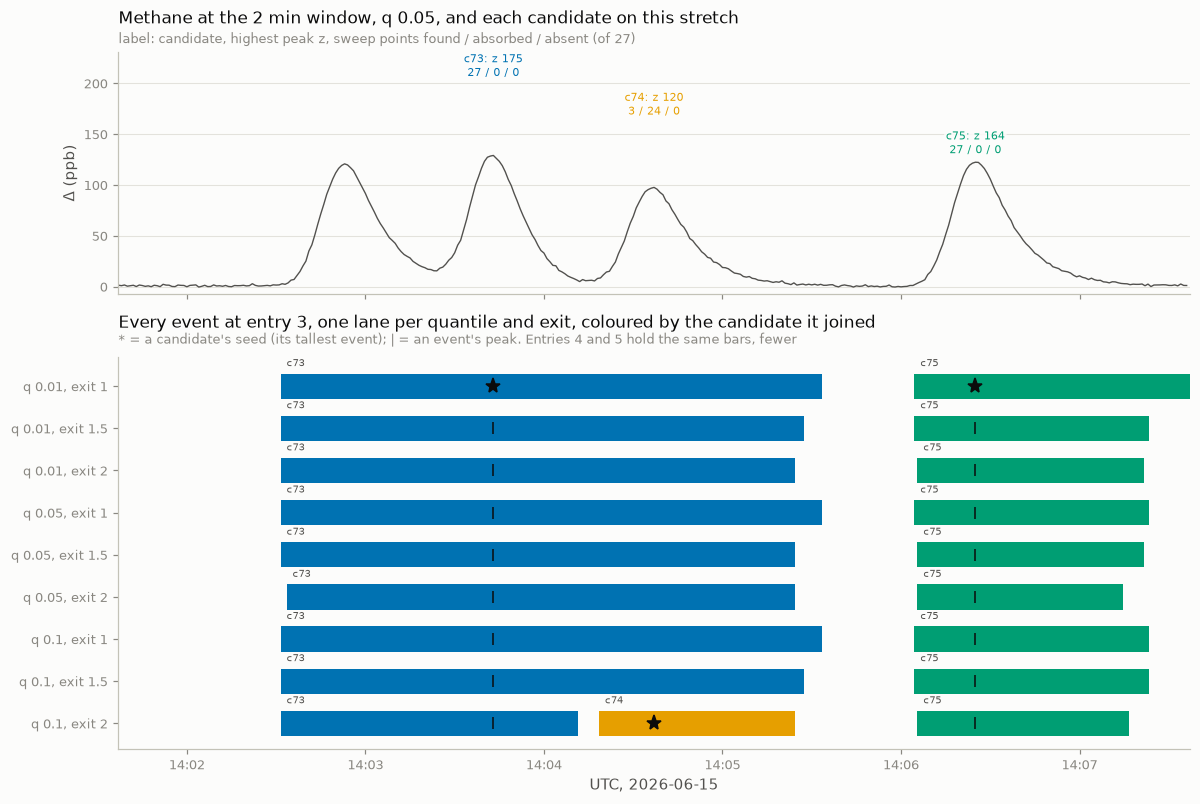


The candidates on this stretch:
               seed found at  highest z  lowest z  found  absorbed  absent
c73  q 0.01, entry 3, exit 1      175.2     148.5     27         0       0
c74   q 0.1, entry 3, exit 2      120.2     120.2      3        24       0
c75  q 0.01, entry 3, exit 1      163.7     140.8     27         0       0

c74 is absorbed at q 0.01, entry 3, exit 1: the event there holding its peak (14:04:37) runs 14:02:31-14:05:33, peaks at 14:03:43 and belongs to c73.


In [19]:
start_section("§6")
run = chain("landfill", seed=SEED, duration=DURATION)
cat, table = run.catalog, run.candidates
here = cat[cat.baseline_window == WINDOW]
mine = table[table.baseline_window == WINDOW]
print(
    f"At the {WINDOW / 60:g} min window: {len(here):,} events at 27 sweep points make "
    f"{len(mine)} candidates; {(mine.n_absorbed > 0).sum()} are absorbed at some point"
)

# The stretch: centred on the tall candidate (highest peak z 5 or more) that is
# absorbed at the most sweep points, or on the most absorbed one if none is tall.
tall = mine[mine.max_peak_z >= 5]
pool = tall if (tall.n_absorbed > 0).any() else mine
focus = pool.sort_values(["n_absorbed", "max_peak_z"]).iloc[-1]
start = focus.peak_time - pd.Timedelta(minutes=VIEW_MINUTES / 2)
stop = focus.peak_time + pd.Timedelta(minutes=VIEW_MINUTES / 2)
view = here[(here.enter_multiple == 3.0) & (here.end_time > start) & (here.start_time < stop)]
ids = sorted(view.candidate_id.unique(), key=lambda i: int(i.rsplit("c", 1)[1]))
palette = [C1, C2, C3, C4, "#56b4e9", "#d55e00", "#999999"]
colour = {cid: palette[k % len(palette)] for k, cid in enumerate(ids)}
seeds = set(table.seed_event_id)

fig, (top, bottom) = plt.subplots(
    2, 1, figsize=(11, 7.4), sharex=True, gridspec_kw={"height_ratios": [1.6, 2.6]}
)
sel = (run.times >= np.datetime64(start)) & (run.times < np.datetime64(stop))
delta = run.baseline["enhancement_ch4"].sel(baseline_window=WINDOW, baseline_quantile=0.05).values
top.plot(run.times[sel], delta[sel], color=INK2, lw=0.9)
shown = table.set_index("candidate_id").loc[ids].sort_values("peak_time")
for k, (cid, r) in enumerate(shown.iterrows()):
    if start <= r.peak_time < stop:
        top.annotate(
            f"{cid.rsplit('/', 1)[1]}: z {r.max_peak_z:.0f}\n"
            f"{r.n_found} / {r.n_absorbed} / {r.n_absent}",
            (r.peak_time, 1.0 - 0.16 * (k % 3)),
            xycoords=("data", "axes fraction"),
            ha="center",
            va="top",
            fontsize=7.5,
            color=colour[cid],
            bbox={"boxstyle": "round,pad=0.15", "fc": SURFACE, "ec": "none", "alpha": 0.85},
        )
top.set_ylim(top.get_ylim()[0], top.get_ylim()[1] * 1.7)
finish(
    top,
    f"Methane at the {WINDOW / 60:g} min window, q 0.05, and each candidate on this stretch",
    sub="label: candidate, highest peak z, sweep points found / absorbed / absent (of 27)",
    ylab="Δ (ppb)",
)
points = [(q, x) for q in (0.01, 0.05, 0.10) for x in (1.0, 1.5, 2.0)]
for k, (q, x) in enumerate(points):
    rows = view[(view.baseline_quantile == q) & (view.exit_multiple == x)]
    for _, r in rows.iterrows():
        lane_bars(bottom, rows.loc[[_]], k, colour[r.candidate_id])
        marker = "*" if r.event_id in seeds else "|"
        bottom.plot([r.peak_time], [k], marker, color=INK, ms=10 if marker == "*" else 8)
        if r.end_time - r.start_time > pd.Timedelta(seconds=VIEW_MINUTES * 4):
            bottom.text(
                max(r.start_time, start) + pd.Timedelta(seconds=2),
                k - 0.42,
                r.candidate_id.rsplit("/", 1)[1],
                fontsize=6.5,
                color=INK2,
                va="bottom",
            )
bottom.set_yticks(range(len(points)), [f"q {q:g}, exit {x:g}" for q, x in points])
bottom.set_ylim(len(points) - 0.4, -0.7)
bottom.set_xlim(start, stop)
finish(
    bottom,
    "Every event at entry 3, one lane per quantile and exit, coloured by the candidate it joined",
    sub="* = a candidate's seed (its tallest event); | = an event's peak. "
    "Entries 4 and 5 hold the same bars, fewer",
    grid_axis=None,
)
clock(bottom)
bottom.set_xlabel(f"UTC, {start:%Y-%m-%d}")
fig.tight_layout()
plt.show()

print("\nThe candidates on this stretch:")
listing = shown[(shown.peak_time >= start) & (shown.peak_time < stop)]
seed_rows = cat.set_index("event_id").loc[listing.seed_event_id]
print(
    pd.DataFrame(
        {
            "seed found at": [
                f"q {q:g}, entry {e:g}, exit {x:g}"
                for q, e, x in zip(
                    seed_rows.baseline_quantile, seed_rows.enter_multiple, seed_rows.exit_multiple
                )
            ],
            "highest z": listing.max_peak_z.round(1).to_numpy(),
            "lowest z": listing.min_peak_z.round(1).to_numpy(),
            "found": listing.n_found.to_numpy(),
            "absorbed": listing.n_absorbed.to_numpy(),
            "absent": listing.n_absent.to_numpy(),
        },
        index=[i.rsplit("/", 1)[1] for i in listing.index],
    ).to_string()
)

# One absorbed candidate, explained: where is it absorbed, and into whom?
absorbed_here = listing[listing.n_absorbed > 0]
if len(absorbed_here):
    cid, r = next(iter(absorbed_here.iterrows()))
    found_at = set(
        zip(
            *[
                cat[cat.candidate_id == cid][k]
                for k in ("baseline_quantile", "enter_multiple", "exit_multiple")
            ]
        )
    )
    for (q, e, x), there in here.groupby(["baseline_quantile", "enter_multiple", "exit_multiple"]):
        holder = there[holds(there.start_time, there.end_time, r.peak_time)]
        if (q, e, x) not in found_at and len(holder):
            other = holder.iloc[0]
            name, owner = cid.rsplit("/", 1)[1], other.candidate_id.rsplit("/", 1)[1]
            print(
                f"\n{name} is absorbed at q {q:g}, entry {e:g}, exit {x:g}: the event there "
                f"holding its peak ({r.peak_time:%H:%M:%S}) runs "
                f"{other.start_time:%H:%M:%S}-{other.end_time:%H:%M:%S}, peaks at "
                f"{other.peak_time:%H:%M:%S} and belongs to {owner}."
            )
            break

**Reading the figure.** Each colour is one candidate. Follow one down the
lanes: it has at most one bar per lane, all its bars hold the starred seed's
peak, and the seed holds each bar's peak. Where a colour is missing from a
lane, look at what is there instead. A bar of another colour holding its peak
means the candidate is *absorbed* at that sweep point: usually the low exit
merged it into a taller neighbour. Nothing at all means it is *absent*. The
labels count the 27 sweep points both ways, entries 4 and 5 included, whose
bars are the entry-3 bars of the events tall enough to reach them (§5).

A candidate can also hold more than one plume. Where the air between two never
falls back below exit, at any quantile or exit, no sweep point separates them,
and they are one event everywhere and so one candidate. The candidate says only
what the sweep could tell apart. Whether the plumes inside it share a source is
the question the ratio stage's goodness of fit answers (§2).

Now the rule against its reference, a slow copy written one event at a time
from `METHODS.md` §6.8's paragraph (in the setup cell, sharing no code with
TSARA), over every event of the record at every window.

In [20]:
seed_of = reference_candidates(cat)
seed_of_candidate = dict(zip(table.candidate_id, table.seed_event_id))
package = {e: seed_of_candidate[c] for e, c in zip(cat.event_id, cat.candidate_id)}
check(
    "§6 TSARA's candidates are the reference's, event for event",
    package == seed_of,
    f"{len(cat):,} events in {len(table):,} candidates over three windows",
)
point = ["baseline_quantile", "enter_multiple", "exit_multiple"]
check(
    "§6 a candidate holds at most one event per sweep point",
    not cat.duplicated(["candidate_id", *point]).any(),
)
seed_rows = cat.set_index("event_id").loc[table.seed_event_id]
seed_rows.index = table.candidate_id
joined = cat.join(
    seed_rows[["start_time", "peak_time", "end_time", "peak_z"]], on="candidate_id", rsuffix="_seed"
)
check(
    "§6 every event and its seed hold each other's peak",
    bool(
        (
            holds(joined.start_time, joined.end_time, joined.peak_time_seed)
            & holds(joined.start_time_seed, joined.end_time_seed, joined.peak_time)
        ).all()
    ),
)
check(
    "§6 a candidate's seed is its tallest event", bool((joined.peak_z <= joined.peak_z_seed).all())
)
check(
    "§6 found + absorbed + absent is a window's 27 sweep points, for every candidate",
    bool((table.n_found + table.n_absorbed + table.n_absent == 27).all()),
)

  ✔ §6 TSARA's candidates are the reference's, event for event   [4,176 events in 297 candidates over three windows]
  ✔ §6 a candidate holds at most one event per sweep point
  ✔ §6 every event and its seed hold each other's peak
  ✔ §6 a candidate's seed is its tallest event
  ✔ §6 found + absorbed + absent is a window's 27 sweep points, for every candidate


**Across windows: the tree.** The same blip is seen at 2, 10 and 60 min, and
each window makes its own candidate of it, because a longer window's event may
hold the blip and the broad plume beneath it together. The tree links them: a
candidate's parent is the candidate of its seed's parent, the event at the
nearest longer window holding the seed's peak (Phase 6). Below, a blip riding
on a landfill (of the 2 min candidates holding a gas-line blip's true peak,
the one whose 60 min ancestor is longest), followed up the tree.

In [21]:
blips = run.plumes[run.plumes.source_name == "gas_line"]
by_id = table.set_index("candidate_id")


def ancestry(cid):
    """Return the candidate and its parent, grandparent, ...: ids from the shortest window up."""
    ids = [cid]
    while isinstance(by_id.loc[ids[-1], "parent_candidate_id"], str):
        ids.append(by_id.loc[ids[-1], "parent_candidate_id"])
    return ids


short = table[table.baseline_window == 120.0]
holding = [
    r.candidate_id
    for _, r in short.iterrows()
    if holds(r.start_time, r.end_time, blips.peak_time).any()
]
lines = {cid: ancestry(cid) for cid in holding}
chosen = max(
    holding,
    key=lambda cid: (by_id.loc[lines[cid][-1], "duration_s"], -by_id.loc[cid, "duration_s"]),
)
for cid in lines[chosen]:
    r = by_id.loc[cid]
    print(
        f"  {cid:28s} {r.start_time:%H:%M:%S}-{r.end_time:%H:%M:%S} "
        f"({r.duration_s / 60:5.1f} min), "
        f"peak {r.peak_time:%H:%M:%S}, highest z {r.max_peak_z:6.1f}, found at {r.n_found} of 27"
    )
windows = [float(by_id.loc[cid, "baseline_window"]) for cid in lines[chosen]]
check(
    "§6 each step up the tree is to a longer window, and holds the child's peak",
    windows == sorted(windows)
    and len(set(windows)) == len(windows)
    and all(
        holds(by_id.loc[up, "start_time"], by_id.loc[up, "end_time"], by_id.loc[down, "peak_time"])
        for down, up in zip(lines[chosen], lines[chosen][1:])
    ),
)

  analyzer.ch4/w120s/c28       11:53:40-11:54:42 (  1.0 min), peak 11:54:02, highest z  139.6, found at 27 of 27
  analyzer.ch4/w600s/c31       11:53:40-11:58:37 (  5.0 min), peak 11:57:04, highest z  386.5, found at 27 of 27
  analyzer.ch4/w3600s/c25      11:53:40-12:50:50 ( 57.2 min), peak 12:17:05, highest z  447.6, found at 27 of 27
  ✔ §6 each step up the tree is to a longer window, and holds the child's peak


**What to read off the tree.** At 2 min the candidate is the blip alone,
lasting a minute or two. At 10 and 60 min the candidate holding its peak can
be much longer, because a longer window leaves the landfill air beneath the
blip standing too: the parent's span is the blip *and* what it rides on.
Which window's ratio belongs to which plume is §6.1's open question; 7c fits
each window's candidates, and the tree keeps them linked.

**Try it.**
- `WINDOW = 3600.0`: at 60 min the figure finds a blip's candidate (c24,
  z 178) absorbed at 21 of its 27 sweep points into the landfill's: a 57 min
  event holding the blips and the landfill beneath them, which only the
  highest exit cuts apart. The long window sees the landfill whole, with its
  blips riding inside it.
- `SEED = 11`: another draw. Every check holds whatever the draw; the
  reference and the package agree event for event.

---
## 7. Is a candidate real? Height, not agreement

A candidate is a description, and some candidates are not plumes: a run of
noise above entry, air the clean description placed too low, wander at the
window's own scale. The answer key says which is which, so the question can be
asked directly: what tells a real candidate from a false one?

Two kinds of evidence were candidates for the job. **Agreement**: a real plume
should be found again at other quantiles. **Height**: a real plume stands
tall, and chance rarely does. The answer key decides.

Each candidate is scored as one of three kinds, by the readings inside its
seed's interval:

- **plume**: its seed holds a true plume's peak time;
- **fragment**: its readings carry a true plume of 1σ (0.7 ppb) or more, but
  its seed holds no true peak, e.g. a broad plume's flank seen by a short
  window, or a sub-peak only a high exit separates;
- **false**: no reading inside it carries a true plume of 1σ.

A **control** record (the same recipe with no plumes at all) shows what
chance and wander alone make: every candidate there is false.

In [22]:
# ---- PARAMETERS (section 7) ----
RECORD = (
    "landfill"  # "landfill" (6 h, the seed below), "weak" or "weak, wander" (12 h of weak plumes)
)
SEED = 5  # the landfill recipe's seed
CONTROL_SEED = 1  # the no-plume control's seed
GATE = 5.0  # the height a candidate's highest peak z must reach, in clean spreads

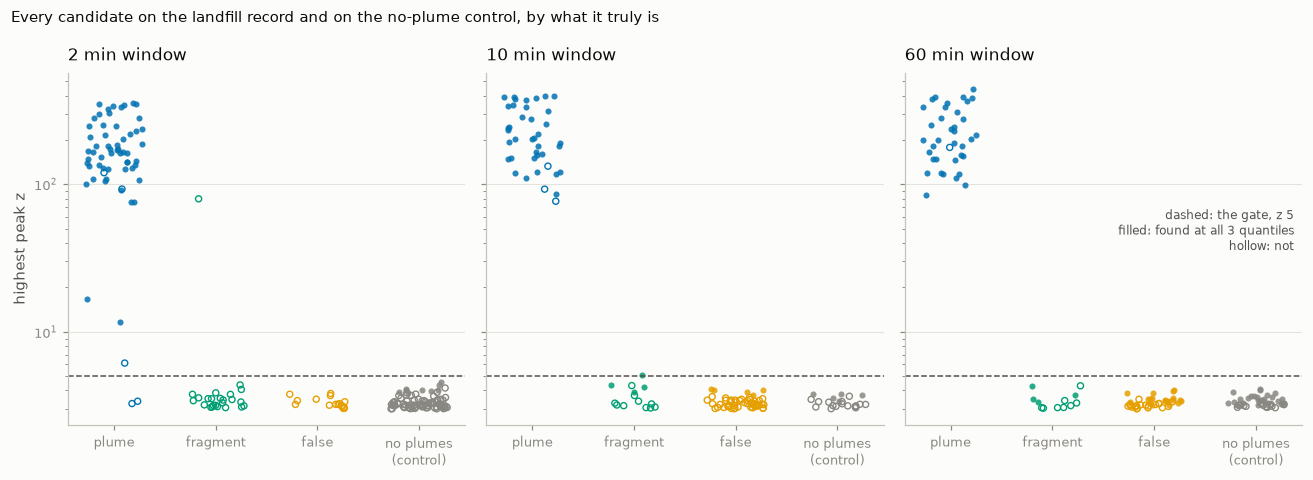

In [23]:
start_section("§7")
if RECORD == "landfill":
    run = chain("landfill", seed=SEED, duration="6h")
else:
    run = chain("weak", seed=1, wander=RECORD == "weak, wander")
control = chain("landfill", seed=CONTROL_SEED, duration="6h", plumes=False)
WINDOWS = (120.0, 600.0, 3600.0)


def scored(r, window):
    """One window's candidates with their kind and the quantiles they reach."""
    table = r.candidates[r.candidates.baseline_window == window].copy()
    seeds = r.catalog.set_index("event_id").loc[table.seed_event_id]
    kinds = []
    for start, end in zip(seeds.start_time, seeds.end_time):
        inside = holds(np.datetime64(start), np.datetime64(end), r.times)
        carries = bool(inside.any() and r.truth[inside].max() >= SIGMA_NOISE)
        peak = bool(holds(start, end, r.plumes.peak_time).any())
        kinds.append("plume" if peak else ("fragment" if carries else "false"))
    table["kind"] = kinds
    quantiles = r.catalog.groupby("candidate_id").baseline_quantile.nunique()
    table["all_quantiles"] = quantiles.loc[table.candidate_id].to_numpy() == 3
    return table


tables = {w: scored(run, w) for w in WINDOWS}
controls = {w: scored(control, w) for w in WINDOWS}

fig, axes = plt.subplots(1, 3, figsize=(12, 4.4), sharey=True)
groups = [("plume", C1), ("fragment", C3), ("false", C2)]
rng = np.random.default_rng(0)  # jitter only
for ax, w in zip(axes, WINDOWS):
    columns = [(kind, tables[w][tables[w].kind == kind], color) for kind, color in groups]
    columns.append(("no plumes\n(control)", controls[w], MUTED))
    for k, (label, rows, color) in enumerate(columns):
        jitter = k + rng.uniform(-0.28, 0.28, len(rows))
        agree = rows.all_quantiles.to_numpy()
        ax.scatter(jitter[agree], rows.max_peak_z[agree], s=16, color=color, lw=0, alpha=0.85)
        ax.scatter(
            jitter[~agree], rows.max_peak_z[~agree], s=16, facecolor="none", edgecolor=color, lw=0.9
        )
    ax.axhline(GATE, color=INK2, ls="--", lw=1)
    ax.set_yscale("log")
    ax.set_xticks(range(4), [label for label, _, _ in columns])
    finish(ax, f"{w / 60:g} min window", ylab="highest peak z" if w == 120.0 else None)
axes[2].text(
    0.98,
    0.55,
    f"dashed: the gate, z {GATE:g}\nfilled: found at all 3 quantiles\nhollow: not",
    transform=axes[2].transAxes,
    fontsize=8,
    color=INK2,
    va="center",
    ha="right",
)
fig.suptitle(
    f"Every candidate on the {RECORD} record and on the no-plume control, by what it truly is",
    x=0.01,
    ha="left",
    fontsize=10,
    color=INK,
)
fig.tight_layout()
plt.show()

**Reading the figure.** Look along the vertical axis first. Plumes stand
tall, up to hundreds of clean spreads; false candidates, on the plume record
and on the control, crowd just above entry 3, nearly all below the gate. Then
look at filled against hollow. Being found at all three quantiles happens to
false candidates too: a run of noise is the same readings at every quantile,
since a lower or higher baseline moves it up or down together. Agreement does
not sort them; height does.

The same, counted: false candidates per hour under a gate on height, and under
agreement across quantiles instead.

In [24]:
def per_hour(r, tables, keep):
    """Return the false candidates an hour that `keep` lets through, at each window."""
    return [round(int((t.kind[keep(t)] == "false").sum()) / r.hours, 2) for t in tables.values()]


gates = {
    "no gate": lambda t: np.ones(len(t), bool),
    f"peak z >= {GATE:g}": lambda t: (t.max_peak_z >= GATE).to_numpy(),
    "found at all 3 quantiles": lambda t: t.all_quantiles.to_numpy(),
}
print("False candidates per hour, at 2 / 10 / 60 min:")
print(f"  {'':26s} {RECORD + ' record':>24s} {'no-plume control':>24s}")
rates = {}
for name, keep in gates.items():
    rates[name] = (per_hour(run, tables, keep), per_hour(control, controls, keep))
    a, b = rates[name]
    left, right = " / ".join(f"{v:.2f}" for v in a), " / ".join(f"{v:.2f}" for v in b)
    print(f"  {name:26s} {left:>24s} {right:>24s}")

# What the gate costs: the share of true plumes an event of a gated candidate holds.
height = (run.plumes.sampled_peak_amplitude / SIGMA_NOISE).to_numpy()
print("\nTrue plumes held by an event of a candidate passing the gate, at 2 / 10 / 60 min:")
for lo, hi in ((3, 5), (5, 10), (10, 30), (30, np.inf)):
    band = (height >= lo) & (height < hi)
    if not band.any():
        continue
    shares = []
    for w, t in tables.items():
        kept = t.candidate_id[(t.max_peak_z >= GATE).to_numpy()]
        members = run.catalog[
            (run.catalog.baseline_window == w) & run.catalog.candidate_id.isin(kept)
        ]
        held = [
            bool(holds(members.start_time, members.end_time, p).any())
            for p in run.plumes.peak_time[band]
        ]
        shares.append(f"{100 * np.mean(held):3.0f} %")
    print(f"  plumes {lo:>2}-{hi:<3} σ tall ({band.sum():2d}): {' / '.join(shares)}")

if (RECORD, SEED, CONTROL_SEED, GATE) == ("landfill", 5, 1, 5.0):
    check(
        "§7 at METHODS' rule the false candidates an hour reproduce §6.8",
        rates["no gate"] == ([2.67, 8.83, 6.67], [13.83, 3.5, 6.83])
        and rates["peak z >= 5"] == ([0.0, 0.0, 0.0], [0.0, 0.0, 0.0])
        and rates["found at all 3 quantiles"] == ([0.0, 0.83, 3.33], [1.5, 0.83, 4.33]),
    )
check(
    "§7 every candidate on the no-plume control is false",
    all((t.kind == "false").all() for t in controls.values()),
    f"{sum(len(t) for t in controls.values())} candidates over three windows",
)

False candidates per hour, at 2 / 10 / 60 min:
                                      landfill record         no-plume control
  no gate                          2.67 / 8.83 / 6.67      13.83 / 3.50 / 6.83
  peak z >= 5                      0.00 / 0.00 / 0.00       0.00 / 0.00 / 0.00
  found at all 3 quantiles         0.00 / 0.83 / 3.33       1.50 / 0.83 / 4.33

True plumes held by an event of a candidate passing the gate, at 2 / 10 / 60 min:
  plumes 30-inf σ tall (73): 100 % / 100 % / 100 %
  ✔ §7 at METHODS' rule the false candidates an hour reproduce §6.8
  ✔ §7 every candidate on the no-plume control is false   [145 candidates over three windows]


**What to take from it.** A gate on height removes nearly every false
candidate, on air with plumes and without, while agreement across quantiles
leaves chance standing. The gate's cost is on weak plumes where the air
wanders, at long windows (try the weak records below); the short windows keep
them, which is one reason the window stays a sweep dimension. So the gate is
the ratio stage's setting, with 5 as its default, and the candidate table keeps
every candidate with its height, so that nothing is hidden (`METHODS.md` §6.8).
The z of the gate is in clean spreads, and chance's rate at a given z grows
with how often the instrument reports: a 10 Hz analyzer makes ten times as many
chance events at the same z as a 1 s one.

**Try it.**
- `RECORD = "weak, wander"`: weak plumes in wandering air. At 60 min the gate
  holds 59 % of the 10–30σ plumes and 27 % of the 5–10σ ones, where at 2 min
  it holds all of them.
- `GATE = 4.0`: a few false candidates pass: 1.17 an hour on the control at
  2 min, 0.50 on the landfill record at 10 min.
- `CONTROL_SEED = 2`: another stretch of plume-free air. The gate at 5 still
  passes none, while agreement across quantiles passes 3.67 / 4.00 / 5.00 an
  hour.

---
## 8. What the ratio stage gets

Sections 1–4 fit lines; sections 5–7 say which events are one thing and how
tall it stood. Phase 7c joins them: a ratio per candidate, fitted over each of
its events, so that the spread of those fits across the sweep is the
methodological part of the ratio's uncertainty (`METHODS.md` §5). Three
properties of the candidates shape how that is done, each measured here.

- **Entry copies are one interval.** An event found at entries 3, 4 and 5 is
  the same interval three times (§5). Fitting each copy would count it three
  times and make the fits look more alike than they are, so 7c fits each
  candidate's *distinct* (quantile, exit) events once: at most 9 per
  candidate with the example sweep.
- **A candidate lives in one window.** A blip found at 2, 10 and 60 min is
  three candidates linked by the tree (§6), and a longer window's candidate
  may hold the plume beneath the blip too. Which window's ratio belongs to
  which plume stays open (`METHODS.md` §6.1).
- **Fragments pass the gate.** A broad plume's flank or a sub-peak can stand
  above z 5 without holding a true plume's peak. Its air is real, and one
  source's, so its ratio is real too; the fit's goodness, not the gate, is what
  judges it.

In [25]:
# ---- PARAMETERS (section 8) ----
SEED = 5  # the landfill recipe's seed
DURATION = "6h"  # the record's length
GATE = 5.0  # the ratio stage's default gate

  ✔ §8 a candidate's events at one quantile and exit are one interval, whatever the entry   [1,183 (candidate, quantile, exit) groups]
138 candidates pass the gate; they hold 3,547 events but 1,183 distinct intervals


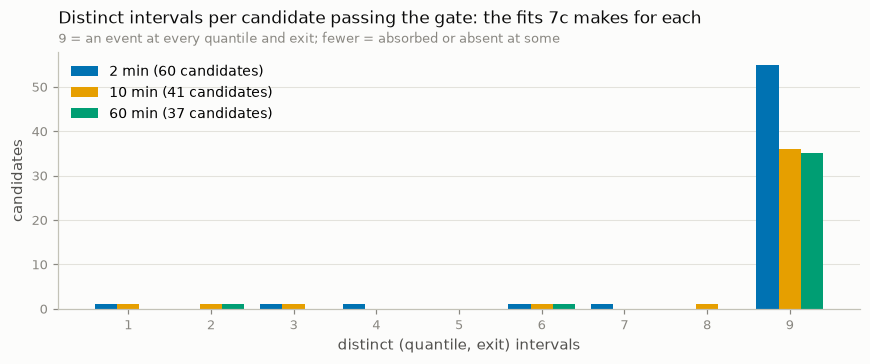

  ✔ §8 no candidate holds more than the 9 (quantile, exit) intervals of a window



Of the 73 true plumes, 73 are held by a gated candidate at all three windows, 0 at two, 0 at one, 0 at none
Fragments passing the gate: 2, 0.33 an hour over the three windows


In [26]:
start_section("§8")
run = chain("landfill", seed=SEED, duration=DURATION)
cat, table = run.catalog, run.candidates
gated = table[table.max_peak_z >= GATE]
members = cat[cat.candidate_id.isin(gated.candidate_id)]

# Entry copies: within a candidate, every event at one (quantile, exit) is one interval.
by_point = members.groupby(["candidate_id", "baseline_quantile", "exit_multiple"])
one_interval = by_point.agg(starts=("start_time", "nunique"), ends=("end_time", "nunique"))
check(
    "§8 a candidate's events at one quantile and exit are one interval, whatever the entry",
    bool(((one_interval.starts == 1) & (one_interval.ends == 1)).all()),
    f"{len(one_interval):,} (candidate, quantile, exit) groups",
)
distinct = by_point.ngroups
print(
    f"{len(gated)} candidates pass the gate; they hold {len(members):,} events "
    f"but {distinct:,} distinct intervals"
)

fits = members.groupby("candidate_id")[["baseline_quantile", "exit_multiple"]].apply(
    lambda g: len(g.drop_duplicates())
)
fig, ax = plt.subplots(figsize=(8, 3.4))
for k, w in enumerate((120.0, 600.0, 3600.0)):
    ids = gated.candidate_id[gated.baseline_window == w]
    counts = np.bincount(fits.loc[ids].to_numpy(), minlength=10)[1:]
    ax.bar(
        np.arange(1, 10) + (k - 1) * 0.27,
        counts,
        width=0.27,
        color=(C1, C2, C3)[k],
        label=f"{w / 60:g} min ({len(ids)} candidates)",
    )
ax.set_xticks(range(1, 10))
finish(
    ax,
    "Distinct intervals per candidate passing the gate: the fits 7c makes for each",
    sub="9 = an event at every quantile and exit; fewer = absorbed or absent at some",
    xlab="distinct (quantile, exit) intervals",
    ylab="candidates",
    legend=True,
    loc="upper left",
)
fig.tight_layout()
plt.show()
check(
    "§8 no candidate holds more than the 9 (quantile, exit) intervals of a window",
    bool((fits <= 9).all()),
)

# A candidate per window: the true plumes held at all three windows.
held = []
for _, p in run.plumes.iterrows():
    windows = [
        w
        for w in (120.0, 600.0, 3600.0)
        if holds(
            members[members.baseline_window == w].start_time,
            members[members.baseline_window == w].end_time,
            p.peak_time,
        ).any()
    ]
    held.append(len(windows))
held = np.array(held)
print(
    f"\nOf the {len(held)} true plumes, {np.sum(held == 3)} are held by a gated candidate "
    f"at all three windows, {np.sum(held == 2)} at two, {np.sum(held == 1)} at one, "
    f"{np.sum(held == 0)} at none"
)

# Fragments: gated candidates whose seed carries a true plume of 1σ but holds no true peak.
seeds = cat.set_index("event_id").loc[gated.seed_event_id]
fragments = 0
for start, end in zip(seeds.start_time, seeds.end_time):
    inside = holds(np.datetime64(start), np.datetime64(end), run.times)
    carries = bool(inside.any() and run.truth[inside].max() >= SIGMA_NOISE)
    fragments += carries and not bool(holds(start, end, run.plumes.peak_time).any())
rate = fragments / run.hours
print(f"Fragments passing the gate: {fragments}, {rate:.2f} an hour over the three windows")

**What to take from it.** The gated candidates hold about three times as many
events as distinct intervals, the entry copies; 7c fits the intervals. Most
candidates have an event at all 9 (quantile, exit) points, and the rest are
absorbed or absent at some. Those differ from point to point, and their
ratios may too, which is exactly the methodological spread 7c measures. Most
true plumes are held at all three windows, each a candidate of its own,
linked by the tree.

**Try it.**
- `GATE = 4.0`: 11 more candidates pass (149 against 138), and 7 of them are
  fragments (9 against 2, 1.50 an hour).
- `SEED = 11`: another draw; the first two checks hold whatever the draw.

---
## Scoreboard

Every check printed above, gathered: each line a claim about TSARA, compared
as it ran against a reference written independently in this notebook.

In [27]:
held = sum(ok for ok, _ in CHECKS.values())
print(f"{held} of {len(CHECKS)} checks hold\n")
for claim, (ok, detail) in CHECKS.items():
    print(f"  {'✔' if ok else '✘'} {claim}" + (f"   [{detail}]" if detail else ""))

31 of 31 checks hold

  ✔ §1 York's line through one event is York's paper written out by hand   [slope 0.049677 vs 0.049677]
  ✔ §1 least squares through one event is the textbook formula
  ✔ §1 every event's York fit holds a line or says why not   [2000 of 2000 fitted]
  ✔ §1 least squares reads the ratio low, by the factor dilution predicts   [mean 0.0425, predicted 0.0423]
  ✔ §1 York reads the true ratio when methane varies at least as much as its noise   [median 0.0499, true 0.05]
  ✔ §2 York's MSWD is the weighted scatter about its line, written out by hand   [5.2759 vs 5.2759]
  ✔ §2 on single-source events the MSWD averages 1, as χ² says   [mean 0.997]
  ✔ §2 the gate flags single-source events about 1% of the time   [0.5%]
  ✔ §3 a common scale on both σ's leaves every event's line where it was
  ✔ §3 a common scale k divides the MSWD by k² and leaves σ_b·√MSWD unchanged
  ✔ §3 methane's σ × k moves the line exactly as ethane's σ ÷ k: only the ratio counts
  ✔ §3 with the rig